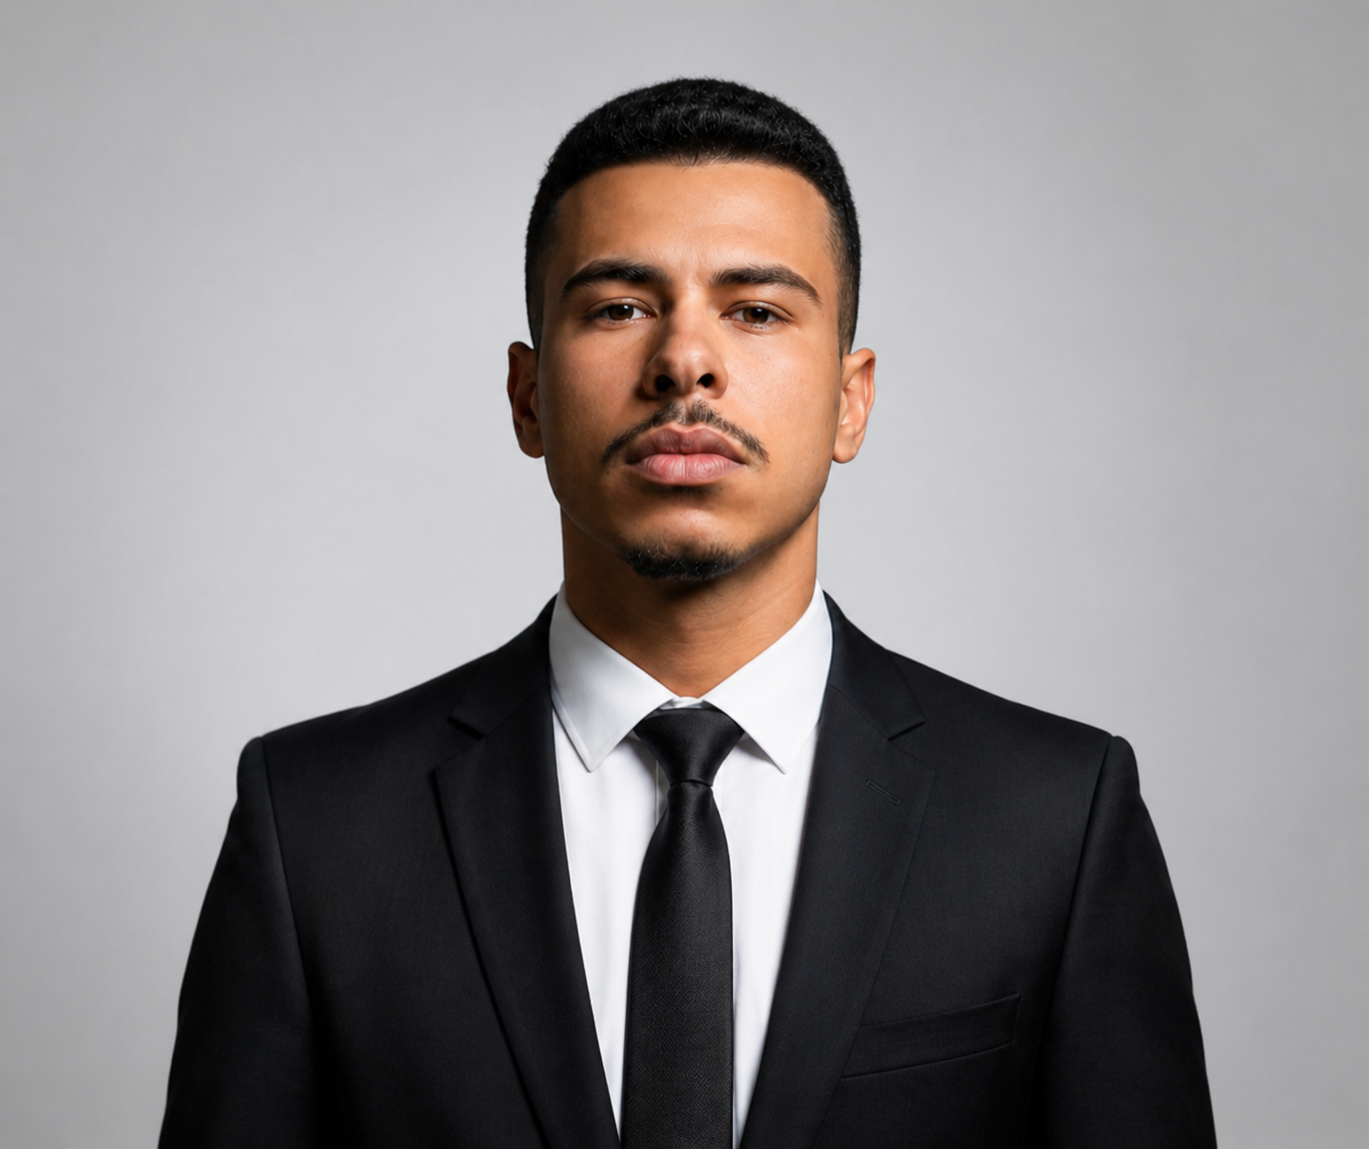

In [105]:
![Ouvrir dans Google Colab](https://colab.research.google.com/assets/colab-badge.svg)(https://colab.research.google.com/github/jawahir-abdelkebir/CC-Partie-A-FIN-3/blob/main/JAWAHIR_ABDELKEBIR_23009247.ipynb)

/bin/bash: -c: line 1: syntax error near unexpected token `('
/bin/bash: -c: line 1: `[Ouvrir dans Google Colab](https://colab.research.google.com/assets/colab-badge.svg)(https://colab.research.google.com/github/jawahir-abdelkebir/CC-Partie-A-FIN-3/blob/main/JAWAHIR_ABDELKEBIR_23009247.ipynb)'


# Partie B — Exploration de 29 algorithmes de Machine Learning

**Notebook complété à partir du fichier fourni.** Les 29 démonstrations initiales sont conservées, avec des réponses Q0–Q4 ajoutées et une partie expérimentale Q5–Q8.

Les exemples initiaux utilisent des jeux publics intégrés à scikit-learn : Diabetes (régression), Breast Cancer Wisconsin (classification), Wine (clustering/anomalies) et Digits (réduction de dimension). Les bandits et Taxi-v3 sont des simulations/environnements interactifs. Les expériences Q5–Q8 ajoutées utilisent des jeux UCI distincts.

**Attention sur les consignes :** le fichier officiel demande d’afficher les données synthétiques en Q0, alors que ce notebook variante utilise surtout des jeux publics réels. Le travail ci-dessous affiche les données réellement utilisées et signale explicitement les simulations ; il ne transforme pas artificiellement les jeux réels en données synthétiques.

**Exécutez toutes les cellules dans l’ordre sur Google Colab.** Les cellules de code n’ont pas été exécutées ici : les sorties et métriques doivent être générées dans Colab et ne sont pas inventées.


# Travail demandé — Partie B (variante)

**Organisation :** binôme · **Public :** L3/Master · **Objectif :** savoir décrire, illustrer, situer et expérimenter **29 algorithmes** sur un second ensemble de cas.

Chaque algorithme doit faire l'objet de **quatre réponses** : présentation scientifique, schéma explicatif original, contexte d'utilisation et analyse de l'expérience. Les réponses ne sont pas fournies dans ce notebook : les codes servent de point de départ.

**Différence avec la Partie A :** nouveaux jeux de données (Diabetes, Breast Cancer, Wine et Digits), paramètres alternatifs, environnement Taxi et questions spécifiques sous chaque titre. Les 29 algorithmes et la structure générale restent identiques.

## Partie A — Questions communes à traiter pour chaque algorithme (1 à 29)

**Q1 — Présentation (8 à 12 lignes).** Donner le type de tâche, l'intuition, les étapes d'apprentissage, une formule essentielle et la **définition de tous ses symboles**. Distinguer paramètres appris et hyperparamètres. Donner deux atouts et deux limites.

**Q2 — Schéma original.** Dessiner un organigramme ou une figure scientifique montrant le chemin des données et le mécanisme de l'algorithme. Ajouter une légende et une explication du schéma. Indiquer la source si une figure extérieure est adaptée.

**Q3 — Contextes d'utilisation.** Décrire deux applications concrètes (au moins une en finance, gestion, logistique ou commerce international), les conditions nécessaires, un cas où la méthode est inappropriée et les métriques adaptées.

**Q4 — Analyse expérimentale.** Exécuter la cellule Python, citer la taille des données et les paramètres, interpréter les métriques et modifier **au moins un hyperparamètre** pour discuter son effet. Ne pas inventer de résultats.

**À ajouter par les étudiants sous chaque algorithme :** « Présentation », « Schéma explicatif », « Contexte d'utilisation », « Analyse et variation d'hyperparamètre ».

## Partie B — Validation finale sur des données publiques

**Q5. Provenance.** Choisir un jeu de données public distinct du cas de démonstration pour chaque famille de méthodes ; préciser la source officielle, l'URL, la date, les dimensions et la cible éventuelle. Une même base peut servir à plusieurs modèles compatibles.

**Q6. Prétraitement.** Identifier les variables manquantes, l'encodage, la standardisation et les éventuelles fuites de données. Ajuster les transformations sur l'entraînement uniquement quand il s'agit de prédire.

**Q7. Essais.** Tester tous les algorithmes adaptés aux données et à la tâche, avec un modèle de référence et un modèle avancé par famille. Séparer train/test (chronologiquement pour les séries temporelles). L'ACP, t-SNE et UMAP sont des outils exploratoires, pas des prédicteurs supervisés.

**Q8. Évaluation et analyse.** Comparer MAE/RMSE/R² (régression), F1/ROC-AUC/PR-AUC (classification, selon le déséquilibre), silhouette/stabilité (clustering), préservation locale (projections) et taux de réussite/récompense (renforcement).

**Note importante :** les bandits et Q-learning/SARSA nécessitent des environnements d'interaction. La démonstration DQN présente la cible de Bellman, **pas** un entraînement d'un réseau neuronal. Un DQN complet est un prolongement facultatif.

**Sources possibles :** [UCI](https://archive.ics.uci.edu/), [OpenML](https://www.openml.org/), [UN Comtrade](https://comtradeplus.un.org/), [Banque mondiale](https://data.worldbank.org/).

## Partie C — Restitution et barème

**Livrables :** (1) notebook complété pour les 29 algorithmes, (2) figures originales et paramètres expliqués, (3) expériences sur données publiques complémentaires, (4) rapport de synthèse de 5 à 8 pages, (5) soutenance en binôme.

**Barème /20 :** rigueur des présentations (5), qualité des 29 schémas (4), pertinence des cas d'usage (3), validité des expérimentations (5), reproductibilité et restitution (3).

**Intégrité :** ne pas confondre simulation et données observées ; citer les sources ; aucune valeur de performance ne doit être inventée ; justifier les changements d'hyperparamètres.

---
## Expérimentations Python de la Partie B

In [106]:
!pip -q install scikit-learn xgboost umap-learn gymnasium

In [107]:
# Jeux publics de scikit-learn : pas de téléchargement ni de compte requis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine, load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, silhouette_score, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
GRAINE = 42

jeu_reg = load_diabetes()
X_reg, y_reg = jeu_reg.data, jeu_reg.target
jeu_cls = load_breast_cancer()
X_cls, y_cls = jeu_cls.data, jeu_cls.target
jeu_groupes = load_wine()
X_clu = StandardScaler().fit_transform(jeu_groupes.data)  # 13 variables standardisées pour le clustering
X_clu_2d = PCA(n_components=2, random_state=GRAINE).fit_transform(X_clu)  # projection réservée à l'affichage
jeu_images = load_digits()
X_images = StandardScaler().fit_transform(jeu_images.data)
Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(X_reg,y_reg,test_size=.25,random_state=GRAINE)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_cls,y_cls,test_size=.25,stratify=y_cls,random_state=GRAINE)
print('Diabetes',X_reg.shape,'Breast cancer',X_cls.shape,'Wine (clustering)',X_clu.shape,'Wine (projection)',X_clu_2d.shape,'Digits',X_images.shape)
print('Exemple Diabetes :\n', pd.DataFrame(X_reg, columns=jeu_reg.feature_names).head())

Diabetes (442, 10) Breast cancer (569, 30) Wine (clustering) (178, 13) Wine (projection) (178, 2) Digits (1797, 64)
Exemple Diabetes :
         age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  


# Complément pédagogique : schémas originaux

La fonction suivante produit un diagramme original à partir des étapes propres à chaque méthode. Elle est appelée sous chacun des 29 algorithmes.


In [108]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def schema_principe(etapes, titre):
    fig, ax = plt.subplots(figsize=(12, 2.8))
    ax.set_xlim(0, len(etapes)*2.6); ax.set_ylim(0, 2); ax.axis('off')
    for i, texte in enumerate(etapes):
        x = i*2.6 + .12
        boite = FancyBboxPatch((x,.65),2.1,.75,boxstyle='round,pad=0.08',fc='#eaf2f8',ec='#24527a',lw=1.4)
        ax.add_patch(boite); ax.text(x+1.05,1.025,texte,ha='center',va='center',fontsize=9,wrap=True)
        if i < len(etapes)-1:
            ax.add_patch(FancyArrowPatch((x+2.12,1.02),(x+2.48,1.02),arrowstyle='->',mutation_scale=14,color='#333333'))
    ax.set_title(titre,fontsize=13,fontweight='bold'); plt.tight_layout(); plt.show()


## 1. Régression linéaire

**Question ciblée (Partie B) :** Expliquez pourquoi une relation linéaire entre les variables médicales et la cible peut être insuffisante.

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


Dataset : Diabetes — (442, 10)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


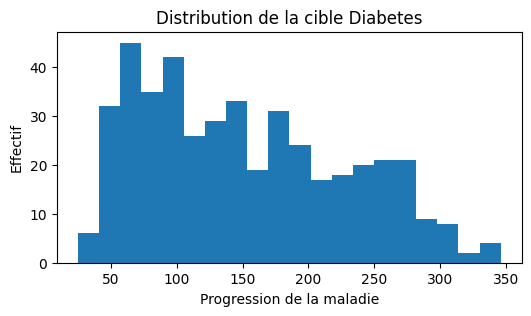

In [109]:
df_q0 = pd.DataFrame(X_reg, columns=jeu_reg.feature_names)
print('Dataset : Diabetes —', df_q0.shape)
display(df_q0.head())
display(df_q0.describe().T)
plt.figure(figsize=(6,3)); plt.hist(y_reg, bins=20); plt.title('Distribution de la cible Diabetes'); plt.xlabel('Progression de la maladie'); plt.ylabel('Effectif'); plt.show()

### Q1 — Présentation

La régression linéaire (*Linear Regression*) est une méthode supervisée de régression qui prédit une variable quantitative à partir de variables explicatives. Elle suppose une relation approximativement linéaire entre les entrées et la cible. Le modèle calcule une combinaison pondérée des variables, puis choisit les coefficients qui minimisent la somme des carrés des résidus. Pour une observation i, la prédiction s’écrit : ŷᵢ = β₀ + Σⱼ βⱼxᵢⱼ. yᵢ désigne la valeur observée, ŷᵢ la prédiction, xᵢⱼ la variable j, β₀ l’interception et βⱼ le coefficient appris. Les β sont des paramètres appris ; l’ajout d’interactions ou de variables est un choix de modélisation. Atouts : modèle rapide et interprétable ; référence simple. Limites : sensible aux valeurs extrêmes et aux relations non linéaires.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Régression linéaire**.


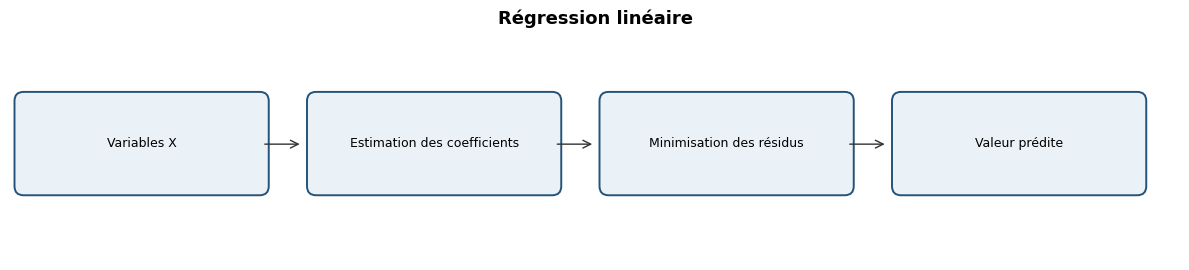

In [110]:
schema_principe(['Variables X', 'Estimation des coefficients', 'Minimisation des résidus', 'Valeur prédite'], titre='Régression linéaire')

### Q3 — Contextes d'utilisation

Prévoir le chiffre d’affaires mensuel à partir des dépenses marketing ; estimer la demande logistique à partir du calendrier et de la météo. Données : cible numérique, variables explicatives numériques/catégorielles encodées, observations suffisamment représentatives. Peu appropriée si la relation est fortement non linéaire ou si les erreurs sont très hétéroscédastiques. Métriques : MAE, RMSE, R² et analyse des résidus.


In [111]:
from sklearn.linear_model import LinearRegression
modele=LinearRegression().fit(Xr_ent,yr_ent)
pred=modele.predict(Xr_test)
print('RMSE:',mean_squared_error(yr_test,pred)**.5,'R²:',r2_score(yr_test,pred))

RMSE: 53.369566710321955 R²: 0.4849058889476756


### Q4 — Analyse de l'expérience Python

Le code entraîne LinearRegression sur Diabetes, avec Xr_ent/yr_ent puis prédit Xr_test. Il affiche RMSE et R². RMSE mesure l’erreur quadratique dans l’unité de la cible ; R² mesure la part de variance expliquée sur le test. Aucun score n’est interprétable avant exécution. Une seule séparation ne prouve pas la stabilité ni la causalité. Variation : comparer LinearRegression à Ridge(alpha=1) sur le même découpage.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [112]:
# Variation de fit_intercept : comparer sur le même test
from sklearn.linear_model import LinearRegression
for intercept in [True, False]:
    m=LinearRegression(fit_intercept=intercept).fit(Xr_ent,yr_ent)
    pr=m.predict(Xr_test)
    print('fit_intercept=',intercept,'RMSE=',mean_squared_error(yr_test,pr)**.5,'R2=',r2_score(yr_test,pr))

fit_intercept= True RMSE= 53.369566710321955 R2= 0.4849058889476756
fit_intercept= False RMSE= 165.27905182745235 R2= -3.9400899456107217


## 2. Ridge

**Question ciblée (Partie B) :** Que se passe-t-il lorsque la pénalisation L2 devient très forte ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


Dataset : Diabetes — (442, 10)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


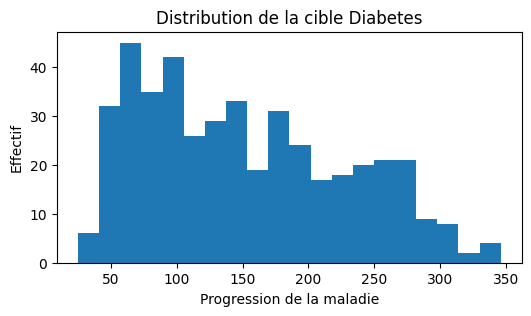

In [113]:
df_q0 = pd.DataFrame(X_reg, columns=jeu_reg.feature_names)
print('Dataset : Diabetes —', df_q0.shape)
display(df_q0.head())
display(df_q0.describe().T)
plt.figure(figsize=(6,3)); plt.hist(y_reg, bins=20); plt.title('Distribution de la cible Diabetes'); plt.xlabel('Progression de la maladie'); plt.ylabel('Effectif'); plt.show()

### Q1 — Présentation

Ridge (*Ridge Regression*) est une régression linéaire régularisée. Elle minimise la somme des carrés des erreurs à laquelle s’ajoute une pénalité L2 sur les coefficients. La fonction objectif est : Σᵢ(yᵢ−ŷᵢ)² + αΣⱼβⱼ². yᵢ est la cible, ŷᵢ la prédiction, βⱼ le coefficient du prédicteur j et α≥0 l’hyperparamètre de régularisation. Les coefficients β sont appris ; α est fixé avant l’apprentissage. Quand α augmente, les coefficients sont davantage contractés, mais généralement pas exactement annulés. Atouts : réduit la variance et stabilise les coefficients corrélés. Limites : conserve en général toutes les variables et nécessite de régler α ; l’échelle des variables compte, d’où la standardisation.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Ridge**.


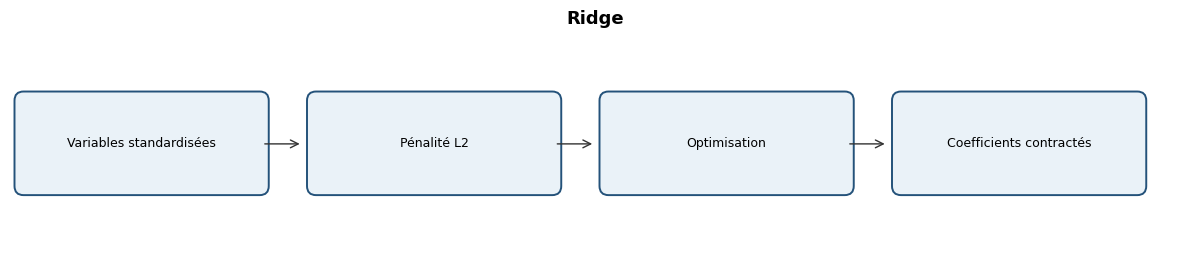

In [114]:
schema_principe(['Variables standardisées', 'Pénalité L2', 'Optimisation', 'Coefficients contractés'], titre='Ridge')

### Q3 — Contextes d'utilisation

Prévoir les ventes à partir de nombreux indicateurs corrélés ; estimer un indicateur financier à partir de ratios comptables. Données : cible continue, variables potentiellement corrélées et échelles harmonisées. Peu appropriée si l’objectif principal est une sélection stricte de variables ou si la relation est très non linéaire. Métriques : MAE, RMSE, R² ; comparer les coefficients et l’erreur de validation.


In [115]:
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),Ridge(alpha=25.)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 41.49082128021844


### Q4 — Analyse de l'expérience Python

Le pipeline standardise les variables puis ajuste Ridge(alpha=25). La MAE est calculée sur le test. La standardisation évite qu’une variable de grande amplitude domine la pénalisation. Un alpha élevé contracte les coefficients ; la MAE seule ne montre pas quels coefficients sont réduits. Variation : tester alpha=1, 25 et 100 sur validation, sans choisir sur le test.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [116]:
from sklearn.linear_model import Ridge
for alpha in [1.,25.,100.]:
    m=make_pipeline(StandardScaler(),Ridge(alpha=alpha)).fit(Xr_ent,yr_ent)
    pr=m.predict(Xr_test); print('alpha=',alpha,'MAE=',mean_absolute_error(yr_test,pr))

alpha= 1.0 MAE= 41.507341526057814
alpha= 25.0 MAE= 41.49082128021844
alpha= 100.0 MAE= 41.927201793643434


## 3. Lasso

**Question ciblée (Partie B) :** Comment la pénalisation L1 sélectionne-t-elle des variables ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


Dataset : Diabetes — (442, 10)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


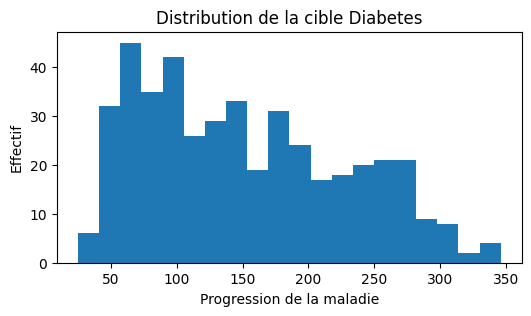

In [117]:
df_q0 = pd.DataFrame(X_reg, columns=jeu_reg.feature_names)
print('Dataset : Diabetes —', df_q0.shape)
display(df_q0.head())
display(df_q0.describe().T)
plt.figure(figsize=(6,3)); plt.hist(y_reg, bins=20); plt.title('Distribution de la cible Diabetes'); plt.xlabel('Progression de la maladie'); plt.ylabel('Effectif'); plt.show()

### Q1 — Présentation

Lasso (*Least Absolute Shrinkage and Selection Operator*) est une régression linéaire régularisée par une pénalité L1. Elle minimise Σᵢ(yᵢ−ŷᵢ)² + αΣⱼ|βⱼ|. yᵢ et ŷᵢ sont les valeurs observée et prédite ; βⱼ est le coefficient de la variable j ; α contrôle la force de la pénalité. Les coefficients β sont appris et α est un hyperparamètre. La pénalité L1 peut rendre certains coefficients exactement nuls, ce qui réalise une sélection automatique de variables. Atouts : modèle relativement interprétable et sélection intégrée. Limites : choix instable entre variables fortement corrélées et forte pénalisation pouvant sous-ajuster. La standardisation est importante.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Lasso**.


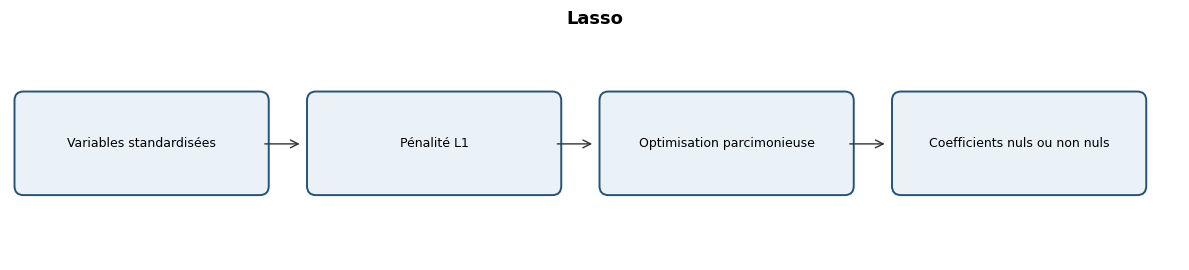

In [118]:
schema_principe(['Variables standardisées', 'Pénalité L1', 'Optimisation parcimonieuse', 'Coefficients nuls ou non nuls'], titre='Lasso')

### Q3 — Contextes d'utilisation

Sélectionner les facteurs associés aux coûts d’exploitation ; identifier les indicateurs qui contribuent à la prévision du risque financier. Données : variables numériques standardisées, cible continue, échantillon assez grand. Peu approprié lorsque les variables sont très corrélées et que l’on souhaite toutes les conserver. Métriques : MAE, RMSE, R², nombre de coefficients non nuls et stabilité de sélection.


In [119]:
from sklearn.linear_model import Lasso
modele=make_pipeline(StandardScaler(),Lasso(alpha=3.,max_iter=15000)).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

R²: 0.5013056660042327


### Q4 — Analyse de l'expérience Python

Le pipeline standardise puis ajuste Lasso(alpha=3). Le R² est calculé sur le test. Les coefficients nuls indiquent les variables écartées par le modèle ; le R² ne révèle pas à lui seul la qualité de sélection. Variation : comparer alpha=.01, .1 et 3, puis compter les coefficients non nuls.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [120]:
from sklearn.linear_model import Lasso
for alpha in [.01,.1,3.]:
    m=make_pipeline(StandardScaler(),Lasso(alpha=alpha,max_iter=20000)).fit(Xr_ent,yr_ent)
    pr=m.predict(Xr_test); print('alpha=',alpha,'R2=',r2_score(yr_test,pr),'coefficients non nuls=',int(np.sum(m[-1].coef_!=0)))

alpha= 0.01 R2= 0.4851097459889827 coefficients non nuls= 10
alpha= 0.1 R2= 0.48659530151144703 coefficients non nuls= 9
alpha= 3.0 R2= 0.5013056660042327 coefficients non nuls= 6


## 4. Régression polynomiale

**Question ciblée (Partie B) :** Quelle difficulté pose la croissance du nombre de caractéristiques polynomiales ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


Dataset : Diabetes — (442, 10)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


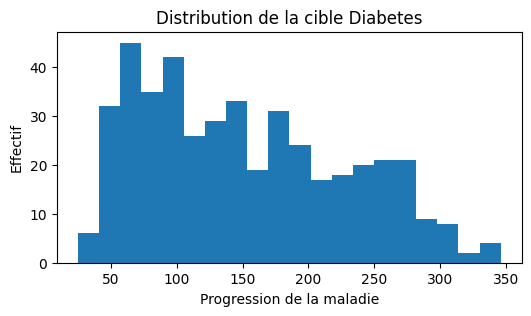

In [121]:
df_q0 = pd.DataFrame(X_reg, columns=jeu_reg.feature_names)
print('Dataset : Diabetes —', df_q0.shape)
display(df_q0.head())
display(df_q0.describe().T)
plt.figure(figsize=(6,3)); plt.hist(y_reg, bins=20); plt.title('Distribution de la cible Diabetes'); plt.xlabel('Progression de la maladie'); plt.ylabel('Effectif'); plt.show()

### Q1 — Présentation

La régression polynomiale (*Polynomial Regression*) étend la régression linéaire en créant des puissances et interactions des variables. Les nouvelles caractéristiques sont ensuite utilisées dans un modèle linéaire. Pour une variable, ŷ=β₀+β₁x+β₂x²+…+β_dxᵈ ; x est l’entrée, d le degré, βⱼ les coefficients appris et ŷ la prédiction. Le degré d et la régularisation sont des hyperparamètres ; les coefficients sont appris. Atouts : capture certaines courbures et reste simple à entraîner. Limites : le nombre de termes croît rapidement et les degrés élevés favorisent le surapprentissage. La validation est indispensable.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Régression polynomiale**.


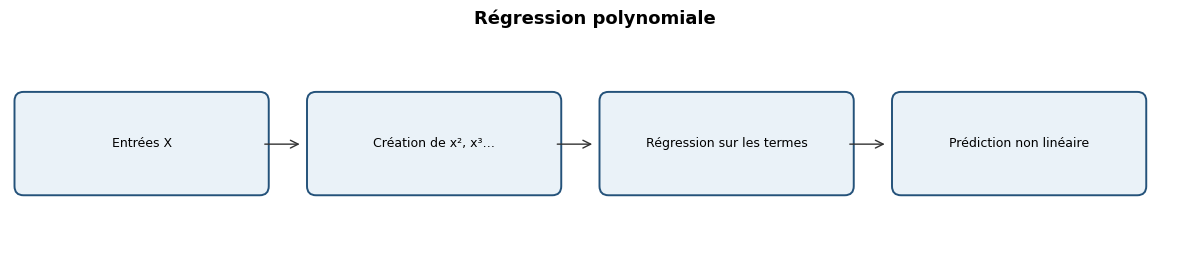

In [122]:
schema_principe(['Entrées X', 'Création de x², x³…', 'Régression sur les termes', 'Prédiction non linéaire'], titre='Régression polynomiale')

### Q3 — Contextes d'utilisation

Prévoir une demande qui varie de façon courbe avec le prix ; modéliser une relation non linéaire entre dépenses commerciales et ventes. Données : variables numériques, taille d’échantillon suffisante, domaine où l’extrapolation reste prudente. Peu appropriée avec beaucoup de variables et peu d’observations. Métriques : MAE, RMSE, R² et comparaison train/validation.


In [123]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),PolynomialFeatures(degree=2,include_bias=False),Ridge(alpha=60.)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 41.24579873763898


### Q4 — Analyse de l'expérience Python

PolynomialFeatures(degree=2) crée les termes quadratiques, puis Ridge(alpha=60) régularise le modèle. La MAE est mesurée sur le test. La dimension transformée peut être nettement supérieure à celle d’origine ; le score seul ne montre pas le coût ni le surapprentissage. Variation : comparer degree=1, 2 et 3 avec une validation.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [124]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
for degree in [1,2,3]:
    m=make_pipeline(StandardScaler(),PolynomialFeatures(degree=degree,include_bias=False),Ridge(alpha=60.)).fit(Xr_ent,yr_ent)
    pr=m.predict(Xr_test); print('degree=',degree,'MAE=',mean_absolute_error(yr_test,pr))

degree= 1 MAE= 41.650472467624944
degree= 2 MAE= 41.24579873763898
degree= 3 MAE= 47.7115915776546


## 5. Arbre de régression

**Question ciblée (Partie B) :** Pourquoi limiter la profondeur et le nombre minimal d’observations par feuille ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


Dataset : Diabetes — (442, 10)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


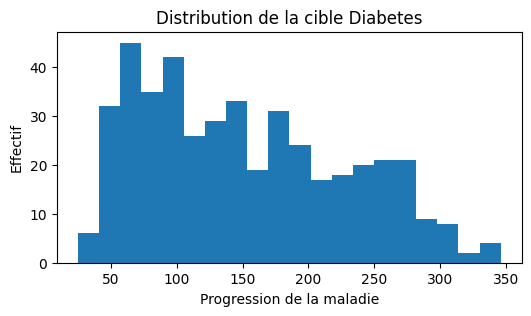

In [125]:
df_q0 = pd.DataFrame(X_reg, columns=jeu_reg.feature_names)
print('Dataset : Diabetes —', df_q0.shape)
display(df_q0.head())
display(df_q0.describe().T)
plt.figure(figsize=(6,3)); plt.hist(y_reg, bins=20); plt.title('Distribution de la cible Diabetes'); plt.xlabel('Progression de la maladie'); plt.ylabel('Effectif'); plt.show()

### Q1 — Présentation

L’arbre de régression (*Decision Tree Regressor*) partitionne l’espace des variables en régions et prédit une valeur constante dans chaque feuille. À chaque nœud, il cherche une coupure qui réduit l’erreur quadratique intra-feuille. Pour une feuille Rₘ, la prédiction est la moyenne des yᵢ appartenant à Rₘ. Rₘ est la région, yᵢ la cible et nₘ le nombre d’observations de la feuille. Les seuils et variables de coupure sont appris ; max_depth et min_samples_leaf sont des hyperparamètres. Atouts : relations non linéaires et interactions, peu de préparation. Limites : forte variance et risque de surapprentissage ; extrapolation médiocre.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Arbre de régression**.


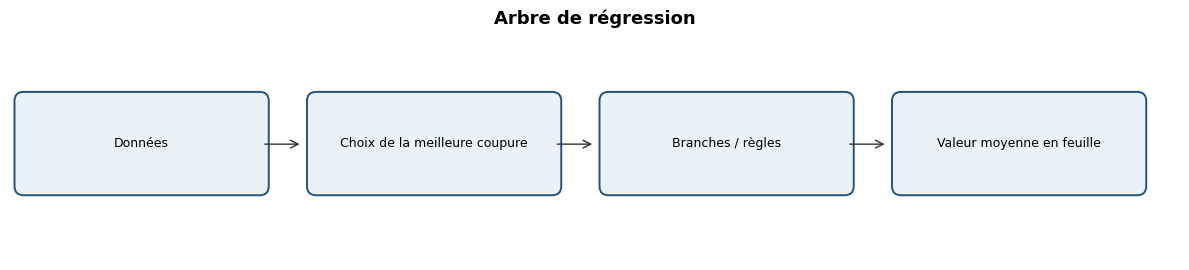

In [126]:
schema_principe(['Données', 'Choix de la meilleure coupure', 'Branches / règles', 'Valeur moyenne en feuille'], titre='Arbre de régression')

### Q3 — Contextes d'utilisation

Prévoir le coût d’un dossier selon ses caractéristiques ; estimer les volumes de stock selon saison, prix et historique. Données : observations tabulaires, cible continue, variables numériques ou catégorielles encodées. Peu approprié pour extrapoler des tendances continues hors de la plage observée. Métriques : MAE, RMSE, R² et profondeur de l’arbre.


In [127]:
from sklearn.tree import DecisionTreeRegressor
modele=DecisionTreeRegressor(max_depth=3,min_samples_leaf=8,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

R²: 0.4314003646672102


### Q4 — Analyse de l'expérience Python

DecisionTreeRegressor utilise max_depth=3 et min_samples_leaf=8 pour limiter la complexité. Le R² est évalué sur le test. Les feuilles prédisent une moyenne ; un R² faible peut signaler un modèle trop simple ou des relations difficiles. Variation : comparer max_depth=2, 3 et 6.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [128]:
from sklearn.tree import DecisionTreeRegressor
for depth in [2,3,6]:
    m=DecisionTreeRegressor(max_depth=depth,min_samples_leaf=8,random_state=GRAINE).fit(Xr_ent,yr_ent)
    print('max_depth=',depth,'RMSE=',mean_squared_error(yr_test,m.predict(Xr_test))**.5)

max_depth= 2 RMSE= 59.54627550946585
max_depth= 3 RMSE= 56.0729846057155
max_depth= 6 RMSE= 61.264567334597615


## 6. Forêt aléatoire — régression

**Question ciblée (Partie B) :** Décrivez le bootstrap et expliquez le rôle de la moyenne des arbres.

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


Dataset : Diabetes — (442, 10)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


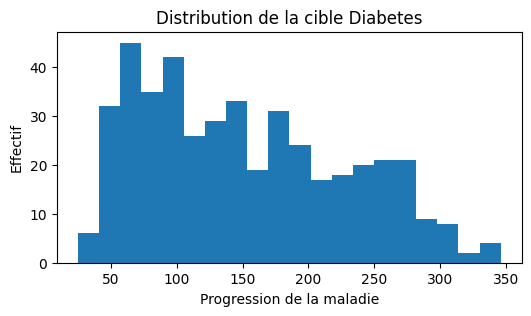

In [129]:
df_q0 = pd.DataFrame(X_reg, columns=jeu_reg.feature_names)
print('Dataset : Diabetes —', df_q0.shape)
display(df_q0.head())
display(df_q0.describe().T)
plt.figure(figsize=(6,3)); plt.hist(y_reg, bins=20); plt.title('Distribution de la cible Diabetes'); plt.xlabel('Progression de la maladie'); plt.ylabel('Effectif'); plt.show()

### Q1 — Présentation

La forêt aléatoire de régression (*Random Forest Regressor*) agrège de nombreux arbres entraînés sur des échantillons bootstrap et des sous-ensembles aléatoires de variables. Chaque arbre produit une prédiction ; la forêt calcule leur moyenne : ŷ(x)=1/B Σᵦ Tᵦ(x). B est le nombre d’arbres et Tᵦ la prédiction du b-ième arbre. Les arbres sont appris ; n_estimators, max_features et min_samples_leaf sont des hyperparamètres. Atouts : réduit la variance d’un arbre et capture des interactions. Limites : modèle moins interprétable, mémoire/calcul plus élevés et extrapolation limitée.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Forêt aléatoire — régression**.


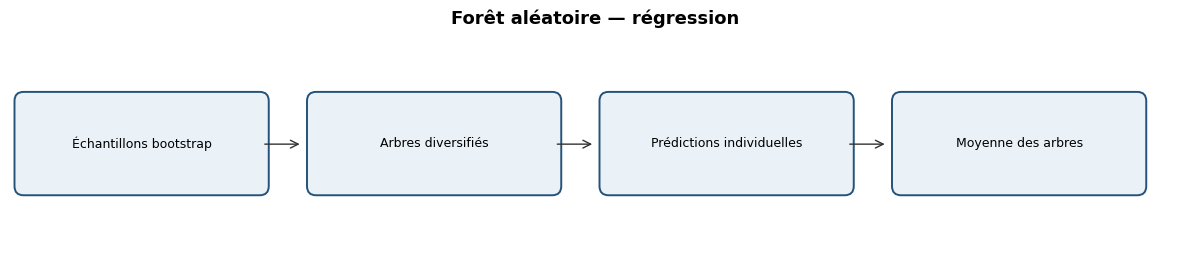

In [130]:
schema_principe(['Échantillons bootstrap', 'Arbres diversifiés', 'Prédictions individuelles', 'Moyenne des arbres'], titre='Forêt aléatoire — régression')

### Q3 — Contextes d'utilisation

Estimer les ventes ou les coûts de transport à partir de facteurs multiples ; prévoir le risque de dépassement budgétaire. Données : tableau structuré, cible numérique, observations indépendantes ou dépendances temporelles traitées. Peu appropriée si une extrapolation lointaine ou une explication causale est requise. Métriques : MAE, RMSE, R², temps d’entraînement.


In [131]:
from sklearn.ensemble import RandomForestRegressor
modele=RandomForestRegressor(n_estimators=120,min_samples_leaf=4,random_state=GRAINE,n_jobs=-1).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 42.58294190565993


### Q4 — Analyse de l'expérience Python

La forêt ajuste 120 arbres avec bootstrap et min_samples_leaf=4, puis affiche la MAE test. La moyenne réduit la variabilité des arbres, sans garantir le meilleur score. Variation : comparer n_estimators=50, 120 et 250, en conservant le même split.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [132]:
from sklearn.ensemble import RandomForestRegressor
for n in [50,120,250]:
    m=RandomForestRegressor(n_estimators=n,min_samples_leaf=4,random_state=GRAINE,n_jobs=-1).fit(Xr_ent,yr_ent)
    print('n_estimators=',n,'MAE=',mean_absolute_error(yr_test,m.predict(Xr_test)))

n_estimators= 50 MAE= 43.16174161324239
n_estimators= 120 MAE= 42.58294190565993
n_estimators= 250 MAE= 42.434104442603186


## 7. Gradient Boosting — régression

**Question ciblée (Partie B) :** Pourquoi les arbres sont-ils entraînés séquentiellement dans le boosting ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


Dataset : Diabetes — (442, 10)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


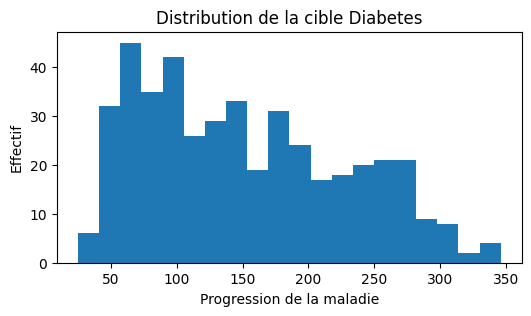

In [133]:
df_q0 = pd.DataFrame(X_reg, columns=jeu_reg.feature_names)
print('Dataset : Diabetes —', df_q0.shape)
display(df_q0.head())
display(df_q0.describe().T)
plt.figure(figsize=(6,3)); plt.hist(y_reg, bins=20); plt.title('Distribution de la cible Diabetes'); plt.xlabel('Progression de la maladie'); plt.ylabel('Effectif'); plt.show()

### Q1 — Présentation

Le gradient boosting de régression (*Gradient Boosting Regressor*) construit une somme additive de petits arbres de manière séquentielle. Chaque nouvel arbre approxime le gradient négatif de la fonction de perte, afin de corriger les erreurs résiduelles du modèle courant. La mise à jour est Fₘ(x)=Fₘ₋₁(x)+ηhₘ(x), où Fₘ est le modèle après m étapes, hₘ le nouvel arbre et η le taux d’apprentissage. Les arbres et leurs poids sont appris ; learning_rate, max_iter et max_leaf_nodes sont des hyperparamètres. Atouts : bonnes performances tabulaires et capture de non-linéarités. Limites : réglage sensible et apprentissage séquentiel plus coûteux.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Gradient Boosting — régression**.


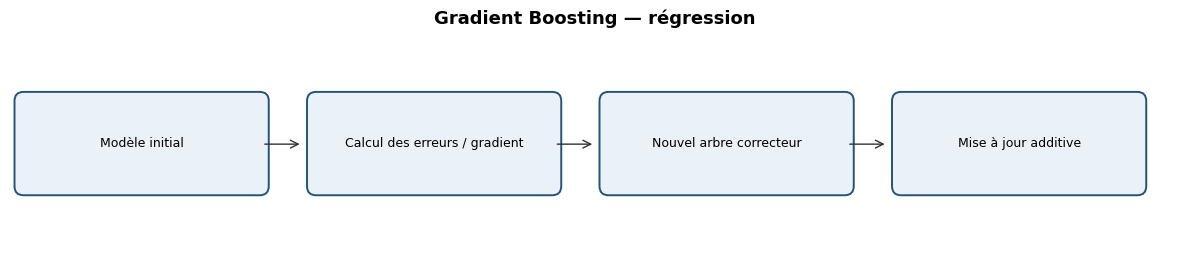

In [134]:
schema_principe(['Modèle initial', 'Calcul des erreurs / gradient', 'Nouvel arbre correcteur', 'Mise à jour additive'], titre='Gradient Boosting — régression')

### Q3 — Contextes d'utilisation

Prévoir les ventes mensuelles et les besoins d’approvisionnement ; estimer les coûts et retards logistiques. Données : tableau tabulaire avec cible numérique et qualité de données contrôlée. Peu approprié pour de très grands flux nécessitant un apprentissage en ligne simple. Métriques : MAE, RMSE, R², temps et validation.


In [135]:
from sklearn.ensemble import HistGradientBoostingRegressor
modele=HistGradientBoostingRegressor(max_iter=110,max_leaf_nodes=12,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('RMSE:',mean_squared_error(yr_test,modele.predict(Xr_test))**.5)

RMSE: 57.12732848789662


### Q4 — Analyse de l'expérience Python

HistGradientBoostingRegressor ajoute jusqu’à 110 itérations avec au plus 12 feuilles par arbre. Le RMSE test pénalise davantage les grandes erreurs. L’entraînement séquentiel corrige progressivement les erreurs, mais aucun gain ne peut être affirmé sans comparaison. Variation : comparer max_iter=50, 110 et 200 sur validation.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [136]:
from sklearn.ensemble import HistGradientBoostingRegressor
for n in [50,110,200]:
    m=HistGradientBoostingRegressor(max_iter=n,max_leaf_nodes=12,random_state=GRAINE).fit(Xr_ent,yr_ent)
    print('max_iter=',n,'RMSE=',mean_squared_error(yr_test,m.predict(Xr_test))**.5)

max_iter= 50 RMSE= 55.60501680668779
max_iter= 110 RMSE= 57.12732848789662
max_iter= 200 RMSE= 58.144901443977844


## 8. Régression logistique

**Question ciblée (Partie B) :** Comment interpréter une probabilité prédite et ajuster le seuil de classification ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


Dataset : Breast Cancer Wisconsin — (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Répartition des classes : {0: 212, 1: 357}


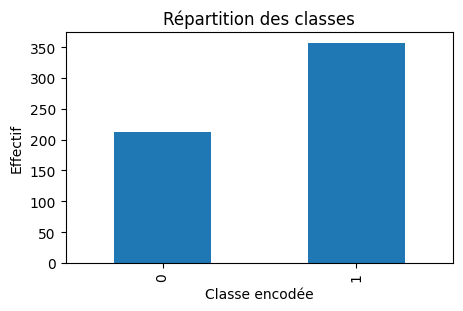

In [137]:
df_q0 = pd.DataFrame(X_cls, columns=jeu_cls.feature_names)
print('Dataset : Breast Cancer Wisconsin —', df_q0.shape)
display(df_q0.head())
print('Répartition des classes :', pd.Series(y_cls).value_counts().sort_index().to_dict())
plt.figure(figsize=(5,3)); pd.Series(y_cls).value_counts().sort_index().plot(kind='bar'); plt.title('Répartition des classes'); plt.xlabel('Classe encodée'); plt.ylabel('Effectif'); plt.show()

### Q1 — Présentation

La régression logistique (*Logistic Regression*) est un classifieur supervisé qui estime la probabilité d’appartenir à une classe. Pour une classification binaire, p(y=1|x)=σ(β₀+βᵀx), avec σ(z)=1/(1+e⁻ᶻ). x est le vecteur des variables, β les coefficients appris, β₀ l’interception et p la probabilité prédite. La classe est déterminée par un seuil, souvent 0,5. Les coefficients sont appris ; C règle l’inverse de la régularisation et le seuil est un choix de décision. Atouts : rapide, probabilités et interprétabilité. Limites : frontière linéaire dans l’espace transformé et sensibilité aux variables mal préparées.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Régression logistique**.


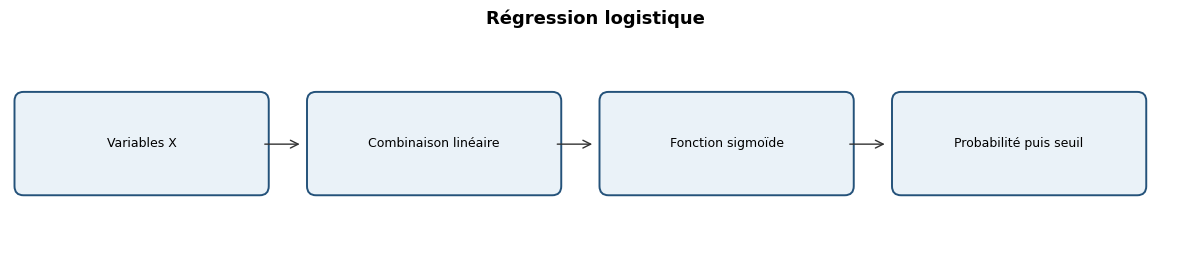

In [138]:
schema_principe(['Variables X', 'Combinaison linéaire', 'Fonction sigmoïde', 'Probabilité puis seuil'], titre='Régression logistique')

### Q3 — Contextes d'utilisation

Prédire la souscription d’un produit bancaire ; classer des dossiers selon un risque de défaut. Données : cible catégorielle, variables numériques/catégorielles encodées, classes représentatives. Peu appropriée si la frontière est fortement non linéaire sans ingénierie de variables. Métriques : précision, rappel, F1, ROC-AUC/PR-AUC et matrice de confusion.


In [139]:
from sklearn.linear_model import LogisticRegression
modele=make_pipeline(StandardScaler(),LogisticRegression(C=.2,max_iter=1500,random_state=GRAINE)).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9888888888888889


### Q4 — Analyse de l'expérience Python

Le pipeline standardise puis ajuste LogisticRegression(C=.2). Le F1 combine précision et rappel pour la classe positive. Le seuil par défaut peut être inadapté si les coûts d’erreur sont asymétriques. Variation : comparer C=.05, .2 et 1 ; le seuil doit être choisi sur validation.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [140]:
from sklearn.linear_model import LogisticRegression
for C in [.05,.2,1.]:
    m=make_pipeline(StandardScaler(),LogisticRegression(C=C,max_iter=2000,random_state=GRAINE)).fit(Xc_ent,yc_ent)
    print('C=',C,'F1=',f1_score(yc_test,m.predict(Xc_test)))

C= 0.05 F1= 0.9726775956284153
C= 0.2 F1= 0.9888888888888889
C= 1.0 F1= 0.9888888888888889


## 9. KNN

**Question ciblée (Partie B) :** Quel est l’effet d’une distance normalisée et du nombre de voisins ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


Dataset : Breast Cancer Wisconsin — (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Répartition des classes : {0: 212, 1: 357}


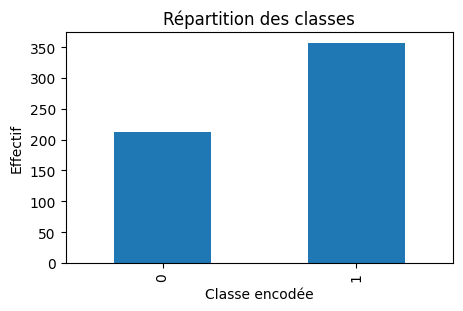

In [141]:
df_q0 = pd.DataFrame(X_cls, columns=jeu_cls.feature_names)
print('Dataset : Breast Cancer Wisconsin —', df_q0.shape)
display(df_q0.head())
print('Répartition des classes :', pd.Series(y_cls).value_counts().sort_index().to_dict())
plt.figure(figsize=(5,3)); pd.Series(y_cls).value_counts().sort_index().plot(kind='bar'); plt.title('Répartition des classes'); plt.xlabel('Classe encodée'); plt.ylabel('Effectif'); plt.show()

### Q1 — Présentation

K plus proches voisins (*K-Nearest Neighbors, KNN*) classe une observation selon les étiquettes de ses k voisins les plus proches. Il ne construit pas de fonction paramétrique pendant l’apprentissage : il mémorise les observations d’entraînement, calcule les distances et vote. La distance euclidienne est d(x,z)=√Σⱼ(xⱼ−zⱼ)². x et z sont deux observations, j indexe les variables et k est un hyperparamètre. La prédiction dépend aussi de la pondération des voisins. Atouts : simple et non linéaire ; peu d’hypothèses. Limites : coûteux à prédire, sensible à l’échelle et à la dimension élevée.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **K plus proches voisins (KNN)**.


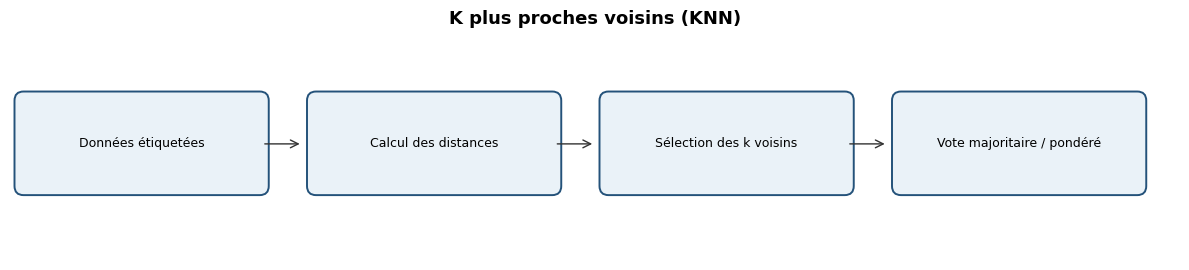

In [142]:
schema_principe(['Données étiquetées', 'Calcul des distances', 'Sélection des k voisins', 'Vote majoritaire / pondéré'], titre='K plus proches voisins (KNN)')

### Q3 — Contextes d'utilisation

Classer les clients selon le comportement d’achats ; détecter des dossiers similaires en gestion de crédit. Données : variables numériques mises à l’échelle, distance pertinente, volume raisonnable. Peu approprié pour des milliers de variables ou des millions de lignes sans indexation. Métriques : précision, rappel, F1, matrice de confusion.


In [143]:
from sklearn.neighbors import KNeighborsClassifier
modele=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=9,weights='distance')).fit(Xc_ent,yc_ent)
print('Exactitude:',accuracy_score(yc_test,modele.predict(Xc_test)))

Exactitude: 0.965034965034965


### Q4 — Analyse de l'expérience Python

Le pipeline standardise les variables et utilise k=9 avec pondération par distance. L’exactitude donne la proportion totale de prédictions correctes, mais peut masquer une classe minoritaire. Variation : comparer k=3, 9 et 15, puis examiner F1 et matrice de confusion.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [144]:
from sklearn.neighbors import KNeighborsClassifier
for k in [3,9,15]:
    m=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=k,weights='distance')).fit(Xc_ent,yc_ent)
    print('k=',k,'F1=',f1_score(yc_test,m.predict(Xc_test)))

k= 3 F1= 0.9782608695652174
k= 9 F1= 0.972972972972973
k= 15 F1= 0.972972972972973


## 10. Naive Bayes

**Question ciblée (Partie B) :** Quelle hypothèse d’indépendance conditionnelle est faite par Naive Bayes ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


Dataset : Breast Cancer Wisconsin — (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Répartition des classes : {0: 212, 1: 357}


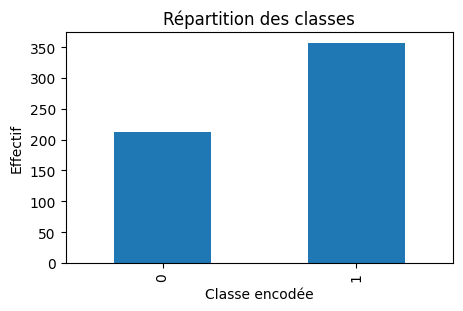

In [145]:
df_q0 = pd.DataFrame(X_cls, columns=jeu_cls.feature_names)
print('Dataset : Breast Cancer Wisconsin —', df_q0.shape)
display(df_q0.head())
print('Répartition des classes :', pd.Series(y_cls).value_counts().sort_index().to_dict())
plt.figure(figsize=(5,3)); pd.Series(y_cls).value_counts().sort_index().plot(kind='bar'); plt.title('Répartition des classes'); plt.xlabel('Classe encodée'); plt.ylabel('Effectif'); plt.show()

### Q1 — Présentation

Naive Bayes gaussien (*Gaussian Naive Bayes*) applique le théorème de Bayes en supposant les variables conditionnellement indépendantes sachant la classe. Il calcule P(y|x) ∝ P(y)∏ⱼP(xⱼ|y). P(y) est la probabilité a priori de la classe et P(xⱼ|y) la vraisemblance de la variable j ; chaque vraisemblance suit une loi normale estimée dans la classe. Les moyennes, variances et a priori sont appris ; var_smoothing stabilise les variances. Atouts : rapide et efficace sur petits jeux. Limites : indépendance souvent irréaliste et probabilités parfois mal calibrées.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Naive Bayes gaussien**.


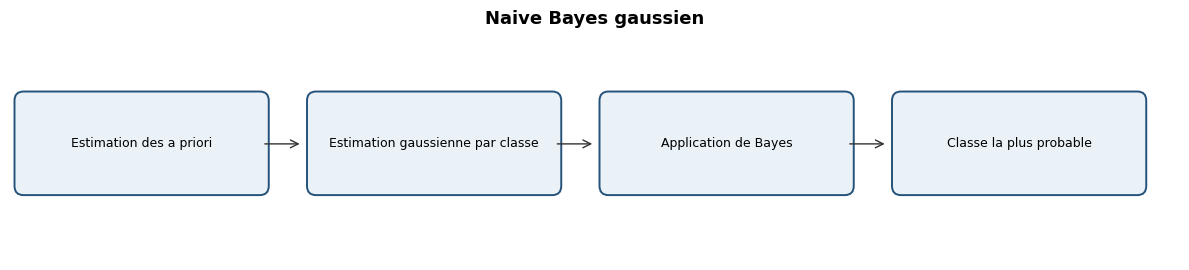

In [146]:
schema_principe(['Estimation des a priori', 'Estimation gaussienne par classe', 'Application de Bayes', 'Classe la plus probable'], titre='Naive Bayes gaussien')

### Q3 — Contextes d'utilisation

Filtrer des demandes commerciales selon leur probabilité de réponse ; classer des documents ou réclamations clients. Données : variables numériques pour la version gaussienne et classes connues. Peu approprié si les variables sont fortement dépendantes et que des probabilités très calibrées sont nécessaires. Métriques : F1, rappel, précision, log-loss et calibration.


In [147]:
from sklearn.naive_bayes import GaussianNB
modele=GaussianNB(var_smoothing=1e-8).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9621621621621622


### Q4 — Analyse de l'expérience Python

GaussianNB estime les distributions par classe et affiche le F1 test. var_smoothing=1e-8 ajoute une petite stabilisation à la variance. La méthode ne nécessite pas de standardisation, mais l’hypothèse gaussienne/indépendance doit être discutée. Variation : tester var_smoothing=1e-9, 1e-8 et 1e-7.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [148]:
from sklearn.naive_bayes import GaussianNB
for v in [1e-9,1e-8,1e-7]:
    m=GaussianNB(var_smoothing=v).fit(Xc_ent,yc_ent)
    print('var_smoothing=',v,'F1=',f1_score(yc_test,m.predict(Xc_test)))

var_smoothing= 1e-09 F1= 0.9513513513513514
var_smoothing= 1e-08 F1= 0.9621621621621622
var_smoothing= 1e-07 F1= 0.9411764705882353


## 11. Arbre de décision

**Question ciblée (Partie B) :** Comment calculer l’impureté de Gini et choisir une séparation ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


Dataset : Breast Cancer Wisconsin — (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Répartition des classes : {0: 212, 1: 357}


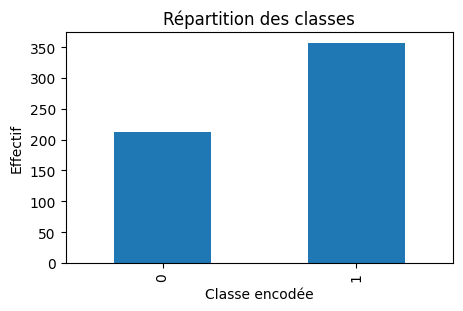

In [149]:
df_q0 = pd.DataFrame(X_cls, columns=jeu_cls.feature_names)
print('Dataset : Breast Cancer Wisconsin —', df_q0.shape)
display(df_q0.head())
print('Répartition des classes :', pd.Series(y_cls).value_counts().sort_index().to_dict())
plt.figure(figsize=(5,3)); pd.Series(y_cls).value_counts().sort_index().plot(kind='bar'); plt.title('Répartition des classes'); plt.xlabel('Classe encodée'); plt.ylabel('Effectif'); plt.show()

### Q1 — Présentation

L’arbre de décision de classification (*Decision Tree Classifier*) sépare récursivement les observations en groupes plus homogènes en classes. Il choisit les coupures qui maximisent la diminution d’impureté, par exemple l’indice de Gini : G=1−Σₖpₖ². pₖ est la proportion de la classe k dans un nœud. Les variables et seuils sont appris ; max_depth et min_samples_leaf sont des hyperparamètres. Une feuille prédit la classe majoritaire ou ses proportions. Atouts : règles lisibles et relations non linéaires. Limites : instabilité et surapprentissage si l’arbre est trop profond.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Arbre de décision — classification**.


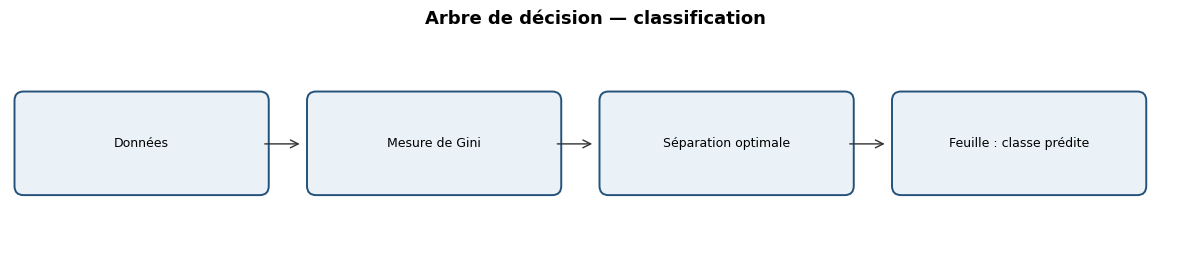

In [150]:
schema_principe(['Données', 'Mesure de Gini', 'Séparation optimale', 'Feuille : classe prédite'], titre='Arbre de décision — classification')

### Q3 — Contextes d'utilisation

Attribuer un niveau de risque à des demandes de crédit ; prévoir la réponse à une campagne marketing. Données : variables tabulaires et cible catégorielle. Peu approprié lorsque la stabilité des règles est essentielle sans contrôle de complexité. Métriques : F1, précision, rappel, ROC-AUC et matrice de confusion.


In [151]:
from sklearn.tree import DecisionTreeClassifier
modele=DecisionTreeClassifier(max_depth=3,min_samples_leaf=5,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9560439560439561


### Q4 — Analyse de l'expérience Python

L’arbre est limité à une profondeur de 3 et 5 observations minimum par feuille. Le F1 est calculé sur le test. La profondeur limite le surapprentissage, mais peut réduire la capacité à représenter des motifs complexes. Variation : comparer max_depth=2, 3 et 6.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [152]:
from sklearn.tree import DecisionTreeClassifier
for depth in [2,3,6]:
    m=DecisionTreeClassifier(max_depth=depth,min_samples_leaf=5,random_state=GRAINE).fit(Xc_ent,yc_ent)
    print('max_depth=',depth,'F1=',f1_score(yc_test,m.predict(Xc_test)))

max_depth= 2 F1= 0.9248554913294798
max_depth= 3 F1= 0.9560439560439561
max_depth= 6 F1= 0.9444444444444444


## 12. Forêt aléatoire — classification

**Question ciblée (Partie B) :** Pourquoi une forêt est-elle généralement moins instable qu’un arbre seul ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


Dataset : Breast Cancer Wisconsin — (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Répartition des classes : {0: 212, 1: 357}


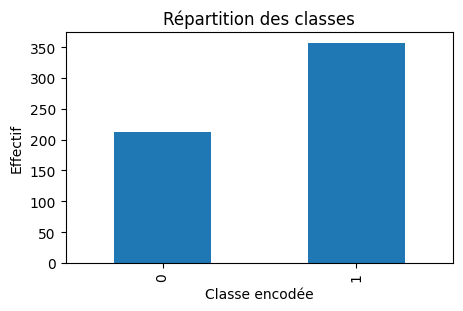

In [153]:
df_q0 = pd.DataFrame(X_cls, columns=jeu_cls.feature_names)
print('Dataset : Breast Cancer Wisconsin —', df_q0.shape)
display(df_q0.head())
print('Répartition des classes :', pd.Series(y_cls).value_counts().sort_index().to_dict())
plt.figure(figsize=(5,3)); pd.Series(y_cls).value_counts().sort_index().plot(kind='bar'); plt.title('Répartition des classes'); plt.xlabel('Classe encodée'); plt.ylabel('Effectif'); plt.show()

### Q1 — Présentation

La forêt aléatoire de classification (*Random Forest Classifier*) combine des arbres appris sur des échantillons bootstrap et des sous-ensembles aléatoires de variables à chaque séparation. Chaque arbre vote pour une classe ; la forêt agrège les votes ou probabilités. La probabilité estimée est p̂ₖ(x)=1/B Σᵦ p̂ₖᵦ(x), où B est le nombre d’arbres et p̂ₖᵦ la probabilité de classe k donnée par l’arbre b. Les arbres sont appris ; n_estimators, max_depth et max_features sont des hyperparamètres. Atouts : robustesse et interactions. Limites : coût, moindre transparence et biais possibles.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Forêt aléatoire — classification**.


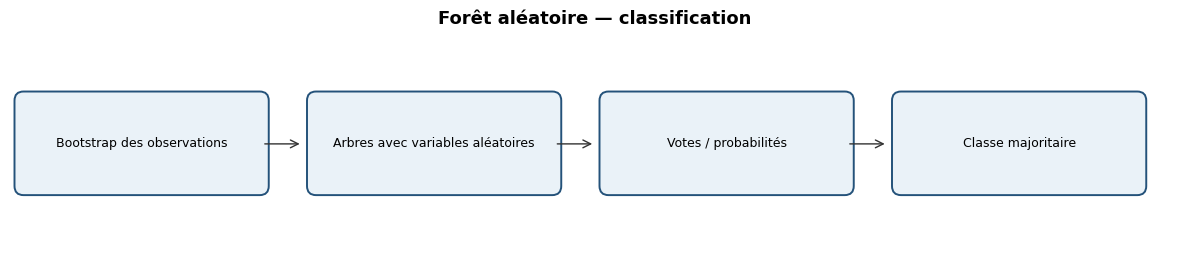

In [154]:
schema_principe(['Bootstrap des observations', 'Arbres avec variables aléatoires', 'Votes / probabilités', 'Classe majoritaire'], titre='Forêt aléatoire — classification')

### Q3 — Contextes d'utilisation

Classer les demandes de financement ; détecter les clients susceptibles de résilier. Données : données tabulaires étiquetées, nettoyage et encodage. Peu appropriée si une explication individuelle simple est impérative. Métriques : F1, précision, rappel, ROC-AUC/PR-AUC et temps de calcul.


In [155]:
from sklearn.ensemble import RandomForestClassifier
modele=RandomForestClassifier(n_estimators=110,max_depth=6,random_state=GRAINE,n_jobs=-1).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9613259668508287


### Q4 — Analyse de l'expérience Python

La forêt contient 110 arbres et limite leur profondeur à 6. Le F1 test résume précision et rappel. L’agrégation tend à réduire la variance d’un arbre isolé, mais ne garantit pas l’absence de biais. Variation : comparer 50, 110 et 200 arbres.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [156]:
from sklearn.ensemble import RandomForestClassifier
for n in [50,110,200]:
    m=RandomForestClassifier(n_estimators=n,max_depth=6,random_state=GRAINE,n_jobs=-1).fit(Xc_ent,yc_ent)
    print('n_estimators=',n,'F1=',f1_score(yc_test,m.predict(Xc_test)))

n_estimators= 50 F1= 0.9613259668508287
n_estimators= 110 F1= 0.9613259668508287
n_estimators= 200 F1= 0.967032967032967


## 13. SVM

**Question ciblée (Partie B) :** À quoi servent les vecteurs de support et le paramètre C ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


Dataset : Breast Cancer Wisconsin — (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Répartition des classes : {0: 212, 1: 357}


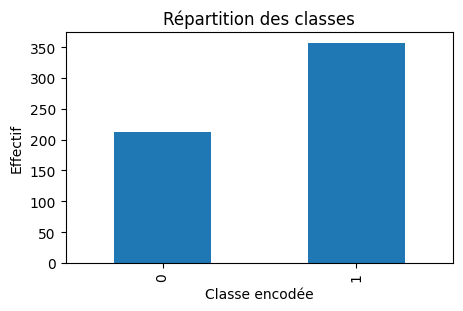

In [157]:
df_q0 = pd.DataFrame(X_cls, columns=jeu_cls.feature_names)
print('Dataset : Breast Cancer Wisconsin —', df_q0.shape)
display(df_q0.head())
print('Répartition des classes :', pd.Series(y_cls).value_counts().sort_index().to_dict())
plt.figure(figsize=(5,3)); pd.Series(y_cls).value_counts().sort_index().plot(kind='bar'); plt.title('Répartition des classes'); plt.xlabel('Classe encodée'); plt.ylabel('Effectif'); plt.show()

### Q1 — Présentation

La machine à vecteurs de support (*Support Vector Machine, SVM*) cherche une frontière séparant les classes avec une marge maximale. Les vecteurs de support sont les observations proches de la frontière. Avec un noyau RBF, la séparation peut être non linéaire. La marge souple minimise ½||w||² + CΣᵢξᵢ sous contraintes, où w définit l’hyperplan, ξᵢ les violations et C le compromis marge/erreurs. C et gamma sont des hyperparamètres ; les vecteurs de support et coefficients sont appris. Atouts : efficace en dimension élevée et noyaux flexibles. Limites : sensible à l’échelle, réglage délicat et coût sur grands jeux.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **SVM**.


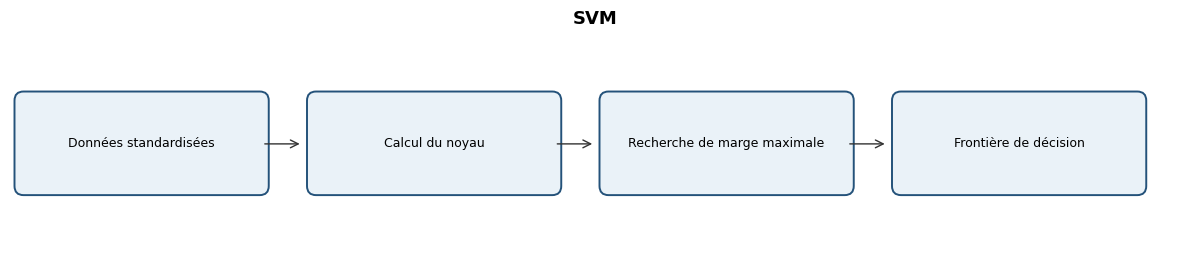

In [158]:
schema_principe(['Données standardisées', 'Calcul du noyau', 'Recherche de marge maximale', 'Frontière de décision'], titre='SVM')

### Q3 — Contextes d'utilisation

Classer les opérations selon un risque ; distinguer les clients susceptibles de répondre à une offre. Données : variables numériques standardisées, étiquettes fiables. Peu approprié pour un très grand nombre d’observations sans approximation. Métriques : F1, précision, rappel, ROC-AUC et temps.


In [159]:
from sklearn.svm import SVC
modele=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=2.,gamma='scale')).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9888888888888889


### Q4 — Analyse de l'expérience Python

SVC utilise un noyau RBF, C=2 et gamma=scale après standardisation. Le F1 est calculé sur le test. La sortie ne montre pas la marge ni les vecteurs de support ; l’échelle et C/gamma influencent la frontière. Variation : comparer C=.5, 2 et 10.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [160]:
from sklearn.svm import SVC
for C in [.5,2.,10.]:
    m=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=C,gamma='scale')).fit(Xc_ent,yc_ent)
    print('C=',C,'F1=',f1_score(yc_test,m.predict(Xc_test)))

C= 0.5 F1= 0.978021978021978
C= 2.0 F1= 0.9888888888888889
C= 10.0 F1= 0.9832402234636871


## 14. Gradient Boosting — classification

**Question ciblée (Partie B) :** Comment corriger progressivement les erreurs de classification ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


Dataset : Breast Cancer Wisconsin — (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Répartition des classes : {0: 212, 1: 357}


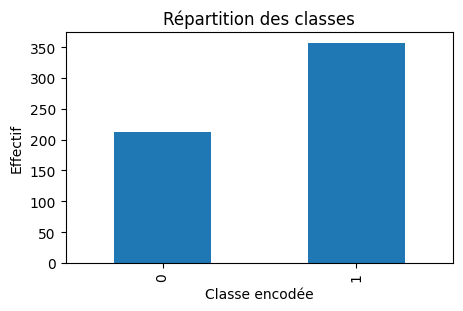

In [161]:
df_q0 = pd.DataFrame(X_cls, columns=jeu_cls.feature_names)
print('Dataset : Breast Cancer Wisconsin —', df_q0.shape)
display(df_q0.head())
print('Répartition des classes :', pd.Series(y_cls).value_counts().sort_index().to_dict())
plt.figure(figsize=(5,3)); pd.Series(y_cls).value_counts().sort_index().plot(kind='bar'); plt.title('Répartition des classes'); plt.xlabel('Classe encodée'); plt.ylabel('Effectif'); plt.show()

### Q1 — Présentation

Le gradient boosting de classification (*Gradient Boosting Classifier*) additionne séquentiellement des apprenants faibles, souvent des arbres, pour réduire une fonction de perte comme la log-loss. Chaque nouvel arbre corrige le gradient négatif de la perte du modèle courant. Une écriture générale est Fₘ(x)=Fₘ₋₁(x)+ηhₘ(x). Fₘ est le score après m étapes, hₘ le nouvel arbre et η le taux d’apprentissage. Les arbres sont appris ; max_iter, learning_rate et max_leaf_nodes sont des hyperparamètres. Atouts : performances tabulaires et flexibilité. Limites : réglage sensible et calcul séquentiel.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Gradient Boosting — classification**.


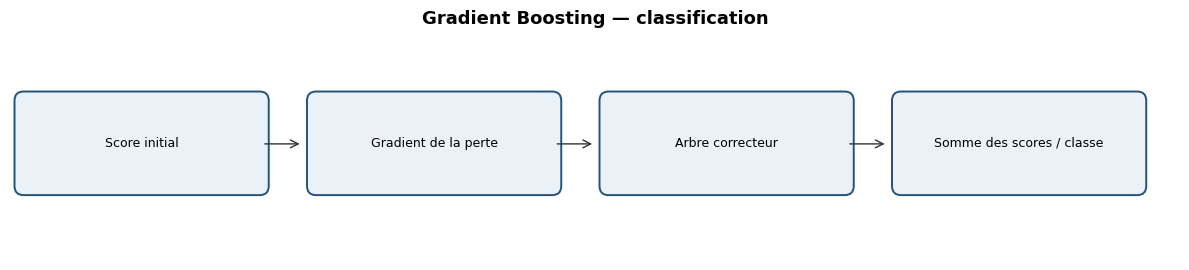

In [162]:
schema_principe(['Score initial', 'Gradient de la perte', 'Arbre correcteur', 'Somme des scores / classe'], titre='Gradient Boosting — classification')

### Q3 — Contextes d'utilisation

Prédire la réponse à une campagne bancaire ; classer les retards de livraison selon les données historiques. Données : tabulaires étiquetées, nettoyage et validation. Peu approprié pour des données massives à très faible latence ou des règles explicatives simples. Métriques : F1, rappel, précision, ROC-AUC/PR-AUC.


In [163]:
from sklearn.ensemble import HistGradientBoostingClassifier
modele=HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=10,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9726775956284153


### Q4 — Analyse de l'expérience Python

HistGradientBoostingClassifier entraîne jusqu’à 100 itérations et 10 feuilles par arbre. Le F1 test évalue la classe positive. Il faut comparer à une référence et surveiller le déséquilibre des classes. Variation : comparer max_iter=50, 100 et 200.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [164]:
from sklearn.ensemble import HistGradientBoostingClassifier
for n in [50,100,200]:
    m=HistGradientBoostingClassifier(max_iter=n,max_leaf_nodes=10,random_state=GRAINE).fit(Xc_ent,yc_ent)
    print('max_iter=',n,'F1=',f1_score(yc_test,m.predict(Xc_test)))

max_iter= 50 F1= 0.9726775956284153
max_iter= 100 F1= 0.9726775956284153
max_iter= 200 F1= 0.9726775956284153


## 15. AdaBoost

**Question ciblée (Partie B) :** Comment AdaBoost repondère-t-il les exemples difficiles ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


Dataset : Breast Cancer Wisconsin — (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Répartition des classes : {0: 212, 1: 357}


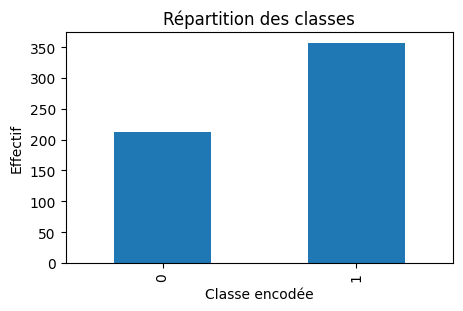

In [165]:
df_q0 = pd.DataFrame(X_cls, columns=jeu_cls.feature_names)
print('Dataset : Breast Cancer Wisconsin —', df_q0.shape)
display(df_q0.head())
print('Répartition des classes :', pd.Series(y_cls).value_counts().sort_index().to_dict())
plt.figure(figsize=(5,3)); pd.Series(y_cls).value_counts().sort_index().plot(kind='bar'); plt.title('Répartition des classes'); plt.xlabel('Classe encodée'); plt.ylabel('Effectif'); plt.show()

### Q1 — Présentation

AdaBoost (*Adaptive Boosting*) construit une série de classifieurs faibles en augmentant le poids des observations mal classées. Après chaque étape, le poids d’un exemple difficile augmente afin que l’apprenant suivant lui accorde plus d’attention. Le poids d’un apprenant peut s’écrire αₘ=½ln((1−errₘ)/errₘ), où errₘ est son erreur pondérée. Les apprenants et leurs poids sont appris ; n_estimators et learning_rate sont des hyperparamètres. Atouts : améliore des apprenants simples et mécanisme pédagogique. Limites : sensible au bruit et aux valeurs atypiques ; risque de surapprentissage avec trop d’étapes.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **AdaBoost**.


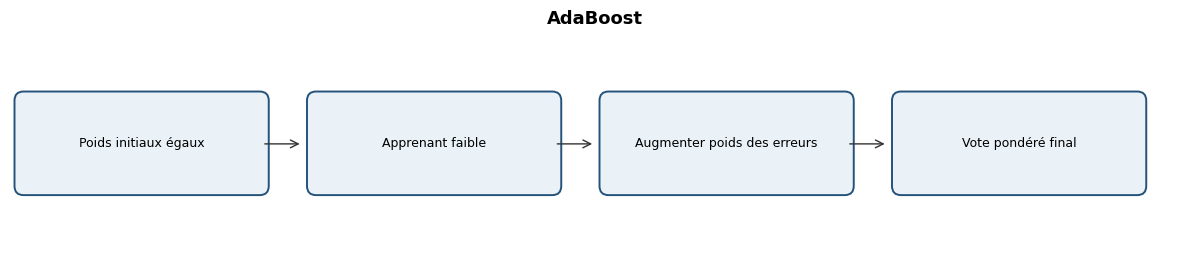

In [166]:
schema_principe(['Poids initiaux égaux', 'Apprenant faible', 'Augmenter poids des erreurs', 'Vote pondéré final'], titre='AdaBoost')

### Q3 — Contextes d'utilisation

Classer les clients répondant à une offre ; identifier les dossiers de gestion nécessitant un contrôle. Données : classes étiquetées, bruit limité, apprenants faibles. Peu approprié si les labels sont très bruités ou si les valeurs aberrantes dominent. Métriques : F1, rappel, précision, ROC-AUC.


In [167]:
from sklearn.ensemble import AdaBoostClassifier
modele=AdaBoostClassifier(n_estimators=90,learning_rate=.7,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9726775956284153


### Q4 — Analyse de l'expérience Python

AdaBoost entraîne 90 apprenants avec learning_rate=.7 et affiche le F1 test. La méthode augmente l’attention accordée aux erreurs successives. La cellule n’affiche pas la trajectoire des poids. Variation : comparer n_estimators=30, 90 et 150.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [168]:
from sklearn.ensemble import AdaBoostClassifier
for n in [30,90,150]:
    m=AdaBoostClassifier(n_estimators=n,learning_rate=.7,random_state=GRAINE).fit(Xc_ent,yc_ent)
    print('n_estimators=',n,'F1=',f1_score(yc_test,m.predict(Xc_test)))

n_estimators= 30 F1= 0.9726775956284153
n_estimators= 90 F1= 0.9726775956284153
n_estimators= 150 F1= 0.967032967032967


## 16. XGBoost

**Question ciblée (Partie B) :** Quel est le rôle de la régularisation et du learning_rate dans XGBoost ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


Dataset : Breast Cancer Wisconsin — (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Répartition des classes : {0: 212, 1: 357}


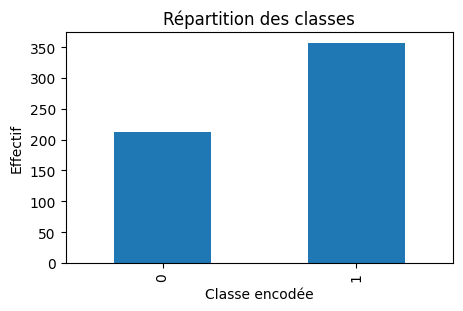

In [169]:
df_q0 = pd.DataFrame(X_cls, columns=jeu_cls.feature_names)
print('Dataset : Breast Cancer Wisconsin —', df_q0.shape)
display(df_q0.head())
print('Répartition des classes :', pd.Series(y_cls).value_counts().sort_index().to_dict())
plt.figure(figsize=(5,3)); pd.Series(y_cls).value_counts().sort_index().plot(kind='bar'); plt.title('Répartition des classes'); plt.xlabel('Classe encodée'); plt.ylabel('Effectif'); plt.show()

### Q1 — Présentation

XGBoost (*Extreme Gradient Boosting*) est une implémentation optimisée du gradient boosting fondée sur des arbres et une fonction objectif régularisée. À chaque itération, un arbre est ajouté pour approximer le gradient de la perte ; la régularisation pénalise la complexité des feuilles. Une forme de l’objectif est L=Σᵢl(yᵢ,ŷᵢ)+γT+½λΣⱼwⱼ². l est la perte, T le nombre de feuilles, wⱼ le score d’une feuille, γ et λ des pénalités. Les arbres sont appris ; learning_rate, max_depth, γ et λ sont des hyperparamètres. Atouts : performant et régularisé. Limites : nombreux réglages, coût et interprétabilité limitée.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **XGBoost**.


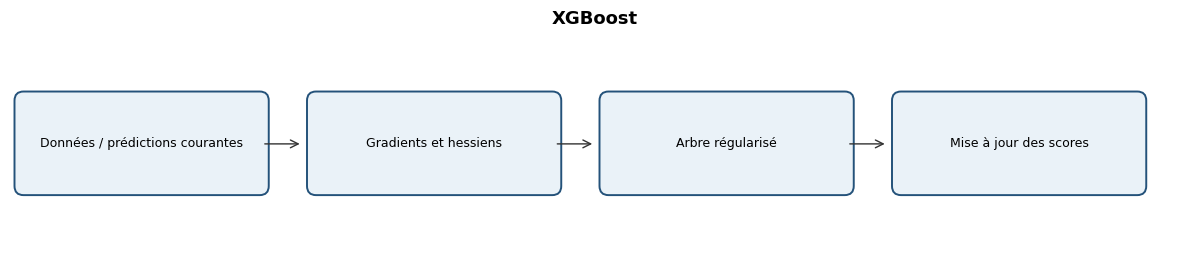

In [170]:
schema_principe(['Données / prédictions courantes', 'Gradients et hessiens', 'Arbre régularisé', 'Mise à jour des scores'], titre='XGBoost')

### Q3 — Contextes d'utilisation

Prévoir le défaut de paiement ; classer les clients selon la probabilité de souscription. Données : tabulaires structurées, cible étiquetée, encodage cohérent. Peu approprié si la transparence complète des décisions est obligatoire sans outil d’explication. Métriques : F1, PR-AUC, ROC-AUC, rappel et temps.


In [171]:
from xgboost import XGBClassifier
modele=XGBClassifier(n_estimators=100,max_depth=2,learning_rate=.09,random_state=GRAINE,eval_metric='logloss').fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.978021978021978


### Q4 — Analyse de l'expérience Python

XGBClassifier entraîne 100 arbres de profondeur 2 avec learning_rate=.09 et logloss. Le F1 est calculé sur le test. La régularisation limite la complexité ; l’évaluation doit inclure PR-AUC si les classes sont déséquilibrées. Variation : comparer learning_rate=.03, .09 et .2 en adaptant n_estimators.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [172]:
from xgboost import XGBClassifier
for lr in [.03,.09,.2]:
    m=XGBClassifier(n_estimators=150,max_depth=2,learning_rate=lr,random_state=GRAINE,eval_metric='logloss').fit(Xc_ent,yc_ent)
    print('learning_rate=',lr,'F1=',f1_score(yc_test,m.predict(Xc_test)))

learning_rate= 0.03 F1= 0.967032967032967
learning_rate= 0.09 F1= 0.9726775956284153
learning_rate= 0.2 F1= 0.9726775956284153


## 17. K-means

**Question ciblée (Partie B) :** Comment affecter chaque vin à son centroïde puis recalculer celui-ci ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


Dataset : Wine — (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,7.943708e-15,1.002821,-2.434235,-0.788245,0.061000,0.836129,2.259772
malic_acid,178.0,3.592632e-16,1.002821,-1.432983,-0.658749,-0.423112,0.669793,3.109192
ash,178.0,-4.066660e-15,1.002821,-3.679162,-0.572122,-0.023821,0.698109,3.156325
alcalinity_of_ash,178.0,-7.983626e-17,1.002821,-2.671018,-0.689137,0.001518,0.602088,3.154511
magnesium,178.0,-7.983626e-17,1.002821,-2.088255,-0.824415,-0.122282,0.509638,4.371372
total_phenols,178.0,-3.991813e-17,1.002821,-2.107246,-0.885468,0.095960,0.808997,2.539515
flavanoids,178.0,9.979533e-16,1.002821,-1.695971,-0.827539,0.106150,0.849085,3.062832
nonflavanoid_phenols,178.0,-5.588538e-16,1.002821,-1.868234,-0.740141,-0.176095,0.609541,2.402403
proanthocyanins,178.0,-1.656602e-15,1.002821,-2.069034,-0.597284,-0.062898,0.629175,3.485073
color_intensity,178.0,-3.442939e-16,1.002821,-1.634288,-0.795103,-0.159225,0.493956,3.435432


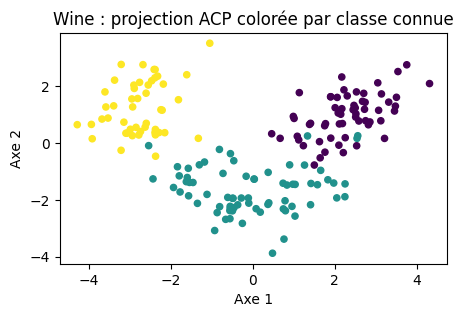

In [173]:
df_q0 = pd.DataFrame(X_clu, columns=jeu_groupes.feature_names)
print('Dataset : Wine —', df_q0.shape)
display(df_q0.head())
display(df_q0.describe().T)
plt.figure(figsize=(5,3)); plt.scatter(X_clu_2d[:,0], X_clu_2d[:,1], c=jeu_groupes.target, cmap='viridis', s=20); plt.title('Wine : projection ACP colorée par classe connue'); plt.xlabel('Axe 1'); plt.ylabel('Axe 2'); plt.show()

### Q1 — Présentation

K-means (*K-means Clustering*) regroupe les observations en K clusters en minimisant la somme des distances quadratiques aux centroïdes. Il alterne affectation de chaque point au centroïde le plus proche et recalcul des moyennes. L’objectif est Σᵢ||xᵢ−μcᵢ||², où xᵢ est une observation, μcᵢ le centroïde du groupe attribué et K le nombre de groupes. Les centroïdes et affectations sont calculés ; K et l’initialisation sont des choix/hyperparamètres. Atouts : rapide et simple. Limites : impose K, sensible à l’échelle, aux valeurs extrêmes et aux formes non sphériques.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **K-means**.


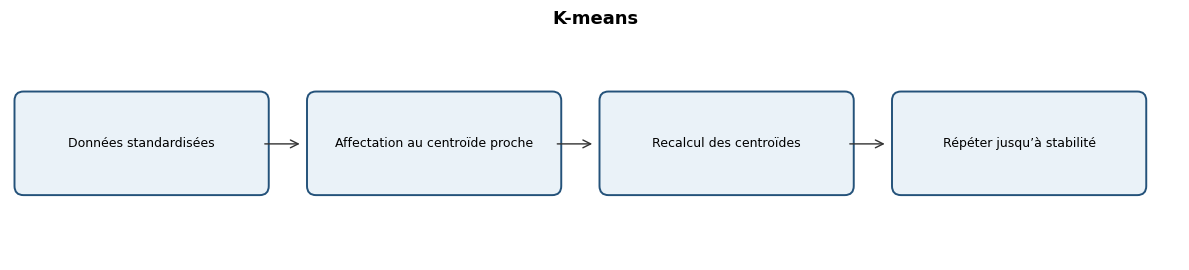

In [174]:
schema_principe(['Données standardisées', 'Affectation au centroïde proche', 'Recalcul des centroïdes', 'Répéter jusqu’à stabilité'], titre='K-means')

### Q3 — Contextes d'utilisation

Segmenter des clients selon les montants d’achat ; regrouper des produits selon les volumes et marges. Données : variables numériques, standardisation et distance euclidienne pertinente. Peu approprié aux groupes très allongés ou de densités différentes. Métriques : silhouette, inertie, stabilité et interprétation métier.


In [ ]:
from sklearn.cluster import KMeans
modele=KMeans(n_clusters=3,n_init=15,random_state=GRAINE).fit(X_clu)
print('Silhouette:',silhouette_score(X_clu,modele.labels_))
plt.scatter(X_clu_2d[:,0],X_clu_2d[:,1],c=modele.labels_,s=22);plt.title('K-means sur Wine : groupes appris en 13D, affichés en ACP 2D');plt.xlabel('Composante 1');plt.ylabel('Composante 2');plt.show()

Silhouette: 0.2848589191898987


### Q4 — Analyse de l'expérience Python

KMeans cherche 3 groupes sur les 13 variables Wine standardisées ; la silhouette compare cohésion et séparation. La figure doit utiliser la projection ACP uniquement pour afficher les groupes, pas pour entraîner le modèle. Variation : tester K=2, 3, 4 et comparer silhouette et interprétabilité.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [ ]:
from sklearn.cluster import KMeans
for k in [2,3,4]:
    m=KMeans(n_clusters=k,n_init=15,random_state=GRAINE).fit(X_clu)
    print('K=',k,'silhouette=',silhouette_score(X_clu,m.labels_))

## 18. Classification hiérarchique

**Question ciblée (Partie B) :** Que montre un dendrogramme et comment définit-on le lien de Ward ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


In [ ]:
df_q0 = pd.DataFrame(X_clu, columns=jeu_groupes.feature_names)
print('Dataset : Wine —', df_q0.shape)
display(df_q0.head())
display(df_q0.describe().T)
plt.figure(figsize=(5,3)); plt.scatter(X_clu_2d[:,0], X_clu_2d[:,1], c=jeu_groupes.target, cmap='viridis', s=20); plt.title('Wine : projection ACP colorée par classe connue'); plt.xlabel('Axe 1'); plt.ylabel('Axe 2'); plt.show()

### Q1 — Présentation

Le clustering hiérarchique agglomératif (*Agglomerative Clustering*) commence avec un cluster par observation puis fusionne progressivement les groupes les plus proches. Avec le lien de Ward, la fusion choisie minimise l’augmentation de la variance intra-cluster. ΔWSS = (nA nB/(nA+nB))||μA−μB||², où nA,nB sont les tailles et μA,μB les centroïdes des groupes A et B. Les fusions sont calculées ; linkage et n_clusters sont des choix. Atouts : hiérarchie interprétable et pas de centroïde initial. Limites : coût mémoire/calcul et choix de coupure parfois subjectif.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Classification hiérarchique**.


In [ ]:
schema_principe(['Chaque point = un groupe', 'Calcul des distances / Ward', 'Fusion progressive', 'Coupe de l’arbre en K groupes'], titre='Classification hiérarchique')

### Q3 — Contextes d'utilisation

Construire des segments de clients B2B ; regrouper des régions selon indicateurs économiques. Données : variables numériques normalisées, métrique adaptée. Peu approprié pour des bases gigantesques ou avec bruit important. Métriques : silhouette, stabilité, dendrogramme et interprétation.


In [ ]:
from sklearn.cluster import AgglomerativeClustering
etiquettes=AgglomerativeClustering(n_clusters=3,linkage='ward').fit_predict(X_clu)
print('Silhouette:',silhouette_score(X_clu,etiquettes))

### Q4 — Analyse de l'expérience Python

AgglomerativeClustering fusionne les observations jusqu’à 3 groupes avec le critère de Ward. La silhouette évalue la séparation. Le code ne dessine pas encore le dendrogramme ; les étiquettes de cluster ne sont pas des classes naturelles connues. Variation : comparer n_clusters=2, 3 et 4.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [ ]:
from sklearn.cluster import AgglomerativeClustering
for k in [2,3,4]:
    lab=AgglomerativeClustering(n_clusters=k,linkage='ward').fit_predict(X_clu)
    print('n_clusters=',k,'silhouette=',silhouette_score(X_clu,lab))

## 19. DBSCAN

**Question ciblée (Partie B) :** À quoi correspondent les points marqués comme bruit par DBSCAN ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


In [ ]:
df_q0 = pd.DataFrame(X_clu, columns=jeu_groupes.feature_names)
print('Dataset : Wine —', df_q0.shape)
display(df_q0.head())
display(df_q0.describe().T)
plt.figure(figsize=(5,3)); plt.scatter(X_clu_2d[:,0], X_clu_2d[:,1], c=jeu_groupes.target, cmap='viridis', s=20); plt.title('Wine : projection ACP colorée par classe connue'); plt.xlabel('Axe 1'); plt.ylabel('Axe 2'); plt.show()

### Q1 — Présentation

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) forme des groupes à partir de régions denses et marque comme bruit les points isolés. Un point est cœur s’il possède au moins min_samples observations dans son voisinage de rayon ε. ε est le rayon, min_samples le seuil de densité ; les groupes sont construits par expansion des points cœur. Les affectations sont calculées, sans centroïdes paramétriques. Atouts : détecte des formes arbitraires et identifie le bruit. Limites : très sensible à ε et à l’échelle ; difficulté si les densités varient fortement.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **DBSCAN**.


In [ ]:
schema_principe(['Calcul du voisinage ε', 'Repérage des points cœur', 'Expansion des groupes', 'Bruit (-1)'], titre='DBSCAN')

### Q3 — Contextes d'utilisation

Détecter des comportements d’achat atypiques ; repérer des zones de concentration de livraisons. Données : variables numériques normalisées et densités suffisamment séparées. Peu approprié si les groupes ont des densités très différentes ou si la dimension est très élevée. Métriques : silhouette hors bruit, proportion de bruit, stabilité et validation métier.


In [ ]:
from sklearn.cluster import DBSCAN
etiquettes=DBSCAN(eps=.7,min_samples=6).fit_predict(X_clu)
print('Groupes:',len(set(etiquettes)-{-1}),'Bruit:',int((etiquettes==-1).sum()))

### Q4 — Analyse de l'expérience Python

DBSCAN utilise eps=.7 et min_samples=6 sur les variables Wine standardisées. Il affiche le nombre de groupes et de points bruités (-1). Le nombre de groupes seul ne prouve pas la qualité. Variation : comparer eps=.5, .7 et .9 en examinant bruit et silhouette si au moins deux groupes existent.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [ ]:
from sklearn.cluster import DBSCAN
for eps in [.5,.7,.9]:
    lab=DBSCAN(eps=eps,min_samples=6).fit_predict(X_clu); mask=lab!=-1; n=len(set(lab[mask]))
    sil=silhouette_score(X_clu[mask],lab[mask]) if n>1 and mask.sum()>n else np.nan
    print('eps=',eps,'groupes=',n,'bruit=',int((~mask).sum()),'silhouette hors bruit=',sil)

## 20. Mélanges gaussiens

**Question ciblée (Partie B) :** En quoi les appartenances probabilistes diffèrent-elles d’une affectation dure ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


In [ ]:
df_q0 = pd.DataFrame(X_clu, columns=jeu_groupes.feature_names)
print('Dataset : Wine —', df_q0.shape)
display(df_q0.head())
display(df_q0.describe().T)
plt.figure(figsize=(5,3)); plt.scatter(X_clu_2d[:,0], X_clu_2d[:,1], c=jeu_groupes.target, cmap='viridis', s=20); plt.title('Wine : projection ACP colorée par classe connue'); plt.xlabel('Axe 1'); plt.ylabel('Axe 2'); plt.show()

### Q1 — Présentation

Le modèle de mélanges gaussiens (*Gaussian Mixture Model, GMM*) suppose que les observations proviennent d’un mélange de K distributions normales. Il estime les paramètres par l’algorithme EM : étape E, probabilités d’appartenance ; étape M, mise à jour des poids, moyennes et covariances. La densité est p(x)=ΣₖπₖN(x|μₖ,Σₖ), où πₖ est le poids, μₖ la moyenne et Σₖ la covariance du composant k. Ces paramètres sont appris ; K et covariance_type sont des hyperparamètres. Atouts : appartenances probabilistes et clusters elliptiques. Limites : hypothèse gaussienne et sensibilité à l’initialisation.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Mélanges gaussiens**.


In [ ]:
schema_principe(['Initialiser K composantes', 'E : probabilités d’appartenance', 'M : mise à jour paramètres', 'Répéter / probabilités finales'], titre='Mélanges gaussiens')

### Q3 — Contextes d'utilisation

Segmenter des portefeuilles clients avec appartenance probabiliste ; modéliser des profils de dépenses par catégories. Données : variables numériques normalisées, nombre de composantes choisi. Peu approprié si les groupes ne ressemblent pas à des distributions gaussiennes. Métriques : silhouette, BIC/AIC, stabilité et interprétation.


In [ ]:
from sklearn.mixture import GaussianMixture
modele=GaussianMixture(n_components=3,covariance_type='full',random_state=GRAINE).fit(X_clu)
etiquettes=modele.predict(X_clu)
print('Poids des groupes:',modele.weights_.round(3),'Silhouette:',silhouette_score(X_clu,etiquettes))

### Q4 — Analyse de l'expérience Python

GaussianMixture ajuste 3 composantes à covariance complète et affiche les poids ainsi que la silhouette des étiquettes les plus probables. Une affectation dure masque l’incertitude disponible via predict_proba. Variation : comparer K=2, 3, 4 et BIC.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [ ]:
from sklearn.mixture import GaussianMixture
for k in [2,3,4]:
    m=GaussianMixture(n_components=k,covariance_type='full',random_state=GRAINE).fit(X_clu); lab=m.predict(X_clu)
    print('K=',k,'BIC=',m.bic(X_clu),'silhouette=',silhouette_score(X_clu,lab))

## 21. ACP

**Question ciblée (Partie B) :** Que mesure la variance expliquée par les deux axes de l’ACP ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


In [ ]:
df_q0 = pd.DataFrame(X_images, columns=[f'pixel_{j}' for j in range(X_images.shape[1])])
print('Dataset : Digits —', df_q0.shape)
display(df_q0.head())
print('Répartition des chiffres :', pd.Series(jeu_images.target).value_counts().sort_index().to_dict())
fig, axes = plt.subplots(1,5,figsize=(9,2))
for ax, image, label in zip(axes, jeu_images.images[:5], jeu_images.target[:5]): ax.imshow(image, cmap='gray'); ax.set_title(f'Chiffre {label}'); ax.axis('off')
plt.tight_layout(); plt.show()

### Q1 — Présentation

L’analyse en composantes principales (*Principal Component Analysis, PCA*) projette des variables corrélées sur des axes orthogonaux qui maximisent successivement la variance expliquée. Après centrage (et souvent standardisation), elle diagonalise la matrice de covariance. La proportion expliquée par la composante j est λⱼ/Σₖλₖ, où λⱼ est sa valeur propre. Les axes principaux sont appris ; n_components et la standardisation sont des choix. Atouts : compression, visualisation et réduction de colinéarité. Limites : relation linéaire, sensibilité à l’échelle et perte d’information.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Analyse en composantes principales (ACP)**.


In [ ]:
schema_principe(['Données centrées / réduites', 'Matrice de covariance', 'Axes de variance maximale', 'Projection sur 2 composantes'], titre='Analyse en composantes principales (ACP)')

### Q3 — Contextes d'utilisation

Réduire les indicateurs financiers avant une analyse de portefeuille ; visualiser des profils de ventes à nombreuses variables. Données : matrice numérique, valeurs manquantes traitées, échelle contrôlée. Peu appropriée si l’information est principalement non linéaire ou si chaque variable doit rester directement interprétable. Métriques : variance expliquée cumulée, reconstruction et qualité de projection.


In [ ]:
from sklearn.decomposition import PCA
modele=PCA(n_components=2,random_state=GRAINE).fit(X_images)
projection=modele.transform(X_images)
print('Variance expliquée:',modele.explained_variance_ratio_.round(3))
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target,cmap='tab10',s=5);plt.title('ACP sur Digits');plt.show()

### Q4 — Analyse de l'expérience Python

PCA projette les 64 pixels de Digits en deux composantes et affiche la variance expliquée. Les couleurs utilisent les vraies étiquettes uniquement pour lire la projection, pas pour entraîner l’ACP. La projection 2D perd de l’information. Variation : comparer 2, 10 et 20 composantes via variance cumulée.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [ ]:
from sklearn.decomposition import PCA
for k in [2,10,20]:
    m=PCA(n_components=k,random_state=GRAINE).fit(X_images)
    print('n_components=',k,'variance cumulée=',m.explained_variance_ratio_.sum())

## 22. t-SNE

**Question ciblée (Partie B) :** Pourquoi la distance entre groupes éloignés peut-elle être trompeuse en t-SNE ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


In [ ]:
df_q0 = pd.DataFrame(X_images, columns=[f'pixel_{j}' for j in range(X_images.shape[1])])
print('Dataset : Digits —', df_q0.shape)
display(df_q0.head())
print('Répartition des chiffres :', pd.Series(jeu_images.target).value_counts().sort_index().to_dict())
fig, axes = plt.subplots(1,5,figsize=(9,2))
for ax, image, label in zip(axes, jeu_images.images[:5], jeu_images.target[:5]): ax.imshow(image, cmap='gray'); ax.set_title(f'Chiffre {label}'); ax.axis('off')
plt.tight_layout(); plt.show()

### Q1 — Présentation

t-SNE (*t-distributed Stochastic Neighbor Embedding*) transforme les proximités de l’espace initial en probabilités puis cherche une projection basse dimension qui conserve surtout les voisinages locaux. Il minimise une divergence de Kullback-Leibler entre distributions de voisinage P et Q : KL(P||Q)=Σᵢⱼpᵢⱼlog(pᵢⱼ/qᵢⱼ). pᵢⱼ et qᵢⱼ sont les probabilités de voisinage dans les espaces initial et projeté. La projection est optimisée ; perplexity, learning_rate et random_state sont des hyperparamètres. Atouts : visualisation de structures locales complexes. Limites : coût, sensibilité aux réglages et distances entre amas globalement peu interprétables.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **t-SNE**.


In [ ]:
schema_principe(['Distances dans l’espace initial', 'Probabilités de voisinage P', 'Optimisation de la projection', 'Carte 2D des voisinages'], titre='t-SNE')

### Q3 — Contextes d'utilisation

Explorer des profils clients à nombreuses variables ; visualiser des catégories de produits ou des comportements de vente. Données : matrice numérique préparée, échantillon raisonnable. Peu approprié pour mesurer des distances globales ou produire directement des prédictions. Métriques : trustworthiness, conservation des k-plus-proches voisins et stabilité visuelle.


In [ ]:
from sklearn.manifold import TSNE
projection=TSNE(n_components=2,perplexity=35,random_state=GRAINE,init='pca').fit_transform(X_images[:600])
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target[:600],cmap='tab10',s=8);plt.title('t-SNE sur Digits');plt.show()

### Q4 — Analyse de l'expérience Python

La cellule applique t-SNE aux 600 premières images Digits, avec perplexity=35 et init=pca. Les couleurs indiquent les chiffres connus à titre descriptif. Les axes n’ont pas d’interprétation métier et les distances entre amas ne doivent pas être surinterprétées. Variation : comparer perplexity=10, 35 et 50.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [ ]:
from sklearn.manifold import TSNE
for perp in [10,35,50]:
    z=TSNE(n_components=2,perplexity=perp,random_state=GRAINE,init='pca').fit_transform(X_images[:600])
    print('perplexity=',perp,'projection=',z.shape)
# Comparer les cartes visuellement ; les coordonnées ne sont pas des métriques de performance.

## 23. UMAP

**Question ciblée (Partie B) :** Quel est l’effet de n_neighbors et min_dist sur les voisinages ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


In [ ]:
df_q0 = pd.DataFrame(X_images, columns=[f'pixel_{j}' for j in range(X_images.shape[1])])
print('Dataset : Digits —', df_q0.shape)
display(df_q0.head())
print('Répartition des chiffres :', pd.Series(jeu_images.target).value_counts().sort_index().to_dict())
fig, axes = plt.subplots(1,5,figsize=(9,2))
for ax, image, label in zip(axes, jeu_images.images[:5], jeu_images.target[:5]): ax.imshow(image, cmap='gray'); ax.set_title(f'Chiffre {label}'); ax.axis('off')
plt.tight_layout(); plt.show()

### Q1 — Présentation

UMAP (*Uniform Manifold Approximation and Projection*) construit un graphe de voisinage dans l’espace initial puis optimise une représentation de faible dimension qui préserve la structure locale. Il estime des relations floues entre voisins et minimise une fonction de cross-entropy entre graphe initial et graphe projeté. n_neighbors contrôle l’échelle du voisinage ; min_dist règle la proximité minimale des points projetés. Les coordonnées sont optimisées ; ces réglages sont des hyperparamètres. Atouts : rapide sur de nombreux jeux et conservation locale utile. Limites : résultats sensibles aux paramètres et distances globales difficiles à interpréter.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **UMAP**.


In [ ]:
schema_principe(['Recherche des voisins', 'Construction du graphe flou', 'Optimisation de la carte', 'Projection basse dimension'], titre='UMAP')

### Q3 — Contextes d'utilisation

Visualiser des segments clients multivariés ; explorer des familles de produits ou de transactions. Données : variables numériques préparées, distance cohérente avec le métier. Peu approprié comme preuve autonome de séparation naturelle ou pour une prédiction supervisée. Métriques : trustworthiness, conservation des voisinages et stabilité selon les graines.


In [ ]:
import umap
projection=umap.UMAP(n_components=2,n_neighbors=20,min_dist=.15,random_state=GRAINE).fit_transform(X_images[:600])
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target[:600],cmap='tab10',s=8);plt.title('UMAP sur Digits');plt.show()

### Q4 — Analyse de l'expérience Python

UMAP projette 600 images Digits en deux dimensions avec n_neighbors=20 et min_dist=.15. Les étiquettes servent à colorer la figure, pas à ajuster la projection. La forme visuelle dépend des paramètres. Variation : comparer n_neighbors=10, 20 et 40 et min_dist=.05, .15.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [ ]:
import umap
for nn in [10,20,40]:
    z=umap.UMAP(n_components=2,n_neighbors=nn,min_dist=.15,random_state=GRAINE).fit_transform(X_images[:600])
    print('n_neighbors=',nn,'projection=',z.shape)
# Comparer la conservation des voisinages / trustworthiness si nécessaire.

## 24. Isolation Forest

**Question ciblée (Partie B) :** Pourquoi une observation statistiquement atypique n’est-elle pas forcément une erreur ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


In [ ]:
df_q0 = pd.DataFrame(X_clu, columns=jeu_groupes.feature_names)
print('Dataset : Wine —', df_q0.shape)
display(df_q0.head())
display(df_q0.describe().T)
plt.figure(figsize=(5,3)); plt.scatter(X_clu_2d[:,0], X_clu_2d[:,1], c=jeu_groupes.target, cmap='viridis', s=20); plt.title('Wine : projection ACP colorée par classe connue'); plt.xlabel('Axe 1'); plt.ylabel('Axe 2'); plt.show()

### Q1 — Présentation

Isolation Forest (*Isolation Forest*) détecte les observations atypiques en construisant des arbres qui isolent les points par des coupures aléatoires. Une anomalie est généralement isolée en moins de divisions qu’une observation normale. Le score repose sur la longueur moyenne de chemin h(x), normalisée par c(n), avec s(x,n)=2^(−E[h(x)]/c(n)). h(x) est la profondeur d’isolement et n la taille d’échantillon. Les arbres sont appris ; n_estimators et contamination sont des hyperparamètres/seuils. Atouts : pas besoin de labels et bonne efficacité tabulaire. Limites : seuil de contamination à justifier et alertes non nécessairement erronées.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Isolation Forest**.


In [ ]:
schema_principe(['Échantillons aléatoires', 'Coupures aléatoires dans des arbres', 'Mesure de profondeur d’isolement', 'Score / alerte atypique'], titre='Isolation Forest')

### Q3 — Contextes d'utilisation

Prioriser les transactions inhabituelles ; détecter des dépenses anormales dans des comptes de gestion. Données : variables numériques, historique représentatif du comportement normal. Peu approprié si les anomalies sont définies par des règles complexes ou si contamination est inconnue sans validation. Métriques : précision/rappel seulement avec labels fiables ; sinon inspection des alertes, stabilité et taux d’alertes.


In [ ]:
from sklearn.ensemble import IsolationForest
# Recherche d'observations atypiques dans les caractéristiques de vins (sans ajouter de faux points)
modele=IsolationForest(contamination=.05,n_estimators=150,random_state=GRAINE).fit(X_clu)
indices=np.where(modele.predict(X_clu)==-1)[0]
print('Nombre de vins atypiques:',len(indices),'Indices (extrait):',indices[:12])

### Q4 — Analyse de l'expérience Python

IsolationForest utilise 150 arbres et contamination=.05 sur les caractéristiques Wine. Il affiche le nombre et quelques indices des observations signalées. Ces points sont atypiques selon le modèle, pas nécessairement erronés ou frauduleux. Variation : comparer contamination=.02, .05 et .10 et examiner les observations signalées.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [ ]:
from sklearn.ensemble import IsolationForest
for cont in [.02,.05,.10]:
    m=IsolationForest(contamination=cont,n_estimators=150,random_state=GRAINE).fit(X_clu)
    print('contamination=',cont,'alertes=',int((m.predict(X_clu)==-1).sum()))

## 25. Bandits manchots

**Question ciblée (Partie B) :** Comment calculer une estimation du gain moyen de chaque bras ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


In [ ]:
print('Bandit : données générées par simulation, pas un dataset observé.')
display(pd.DataFrame({'bras': range(4), 'probabilité_de_succès_simulée': probabilites}))
plt.bar(range(4), probabilites); plt.title('Probabilités de récompense définies dans la simulation'); plt.xlabel('Bras'); plt.ylabel('Probabilité'); plt.show()

### Q1 — Présentation

Le problème des bandits manchots (*Multi-Armed Bandit*) consiste à choisir répétitivement une action parmi plusieurs bras dont les récompenses sont inconnues. L’agent estime la récompense moyenne de chaque bras et doit arbitrer exploration et exploitation. L’estimateur empirique est Q̂ₐ= Sₐ/Nₐ, où Sₐ est la somme des récompenses du bras a et Nₐ son nombre de sélections. Les estimations sont apprises en ligne ; la politique de sélection est un choix. Atouts : formulation simple et décisions adaptatives. Limites : pas d’état complexe et exploration coûteuse ; les résultats dépendent de la stationnarité des récompenses.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Bandits manchots**.


In [ ]:
schema_principe(['Choisir un bras', 'Recevoir une récompense', 'Mettre à jour la moyenne', 'Répéter / comparer les bras'], titre='Bandits manchots')

### Q3 — Contextes d'utilisation

Choisir la meilleure campagne marketing parmi plusieurs offres ; répartir l’exposition entre produits ou canaux publicitaires. Données : récompenses observées après chaque action, environnement avec bras disponibles. Peu approprié si les décisions ont des effets différés complexes ou si les récompenses ne sont pas observables. Métriques : récompense cumulée, regret cumulé, fréquence de sélection.


In [ ]:
# Bandit simulé à 4 choix : la politique choisit successivement chaque bras
generateur=np.random.default_rng(GRAINE)
probabilites=np.array([.15,.4,.6,.75]);sommes=np.zeros(4);comptes=np.zeros(4,dtype=int)
for t in range(800):
    bras=t%4
    gain=int(generateur.random()<probabilites[bras]);sommes[bras]+=gain;comptes[bras]+=1
print('Probabilités estimées:',(sommes/comptes).round(3))

### Q4 — Analyse de l'expérience Python

La cellule simule quatre bras Bernoulli dont les probabilités sont fixées artificiellement, puis les sélectionne à tour de rôle. Les moyennes estimées doivent approcher les probabilités de la simulation à mesure que les essais augmentent. Ce n’est pas un dataset réel ni une expérience de terrain. Variation : modifier le nombre de tirages et comparer les estimations à la vérité simulée.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [ ]:
# Variation de l'horizon dans le bandit simulé : moyenne empirique par bras
for horizon in [400,800,1600]:
    rng=np.random.default_rng(GRAINE); p=np.array([.15,.4,.6,.75]); s=np.zeros(4); n=np.zeros(4)
    for t in range(horizon):
        a=t%4; s[a]+=int(rng.random()<p[a]); n[a]+=1
    print('horizon=',horizon,'estimations=',np.round(s/n,3))

## 26. Epsilon-greedy

**Question ciblée (Partie B) :** Quelle différence entre exploration aléatoire et exploitation du meilleur bras estimé ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


In [ ]:
print('Bandit : données générées par simulation, pas un dataset observé.')
display(pd.DataFrame({'bras': range(4), 'probabilité_de_succès_simulée': probabilites}))
plt.bar(range(4), probabilites); plt.title('Probabilités de récompense définies dans la simulation'); plt.xlabel('Bras'); plt.ylabel('Probabilité'); plt.show()

### Q1 — Présentation

Epsilon-greedy est une politique pour les bandits qui explore aléatoirement avec probabilité ε et exploite le bras dont la récompense estimée est la meilleure avec probabilité 1−ε. L’estimation moyenne est Q̂ₐ=Sₐ/Nₐ. Sₐ est la somme des récompenses et Nₐ le nombre de sélections du bras a. ε est un hyperparamètre de politique ; les estimations Q̂ sont apprises en ligne. Atouts : très simple et garantit une exploration minimale. Limites : exploration parfois inutile persistante et sensibilité à ε ; ne tient pas compte de l’incertitude des estimations.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Epsilon-greedy**.


In [ ]:
schema_principe(['Estimer les récompenses', 'Tirage aléatoire < ε ?', 'Explorer ou exploiter', 'Mettre à jour les estimations'], titre='Epsilon-greedy')

### Q3 — Contextes d'utilisation

Optimiser progressivement les campagnes marketing ; tester des recommandations de produits en limitant le gaspillage d’impressions. Données : récompense immédiate et bras disponibles. Peu approprié si les contextes utilisateurs changent fortement sans bandit contextuel. Métriques : récompense cumulée, regret, taux d’exploration et fréquence par bras.


In [ ]:
# Epsilon-greedy sur les mêmes 4 bras simulés
generateur=np.random.default_rng(GRAINE)
probabilites=np.array([.15,.4,.6,.75]);sommes=np.zeros(4);comptes=np.zeros(4,dtype=int);epsilon=.15
for t in range(1200):
    bras=int(generateur.integers(4)) if generateur.random()<epsilon else int(np.argmax((sommes+1)/(comptes+2)))
    gain=int(generateur.random()<probabilites[bras]);sommes[bras]+=gain;comptes[bras]+=1
print('Nombre de choix:',comptes,'Estimations:',(sommes/np.maximum(comptes,1)).round(3))

### Q4 — Analyse de l'expérience Python

La politique utilise ε=.15 pendant 1 200 décisions dans un bandit artificiel à quatre bras. Le tableau affiche les sélections et les gains moyens estimés. Le bras le plus souvent choisi n’est pas nécessairement le meilleur sur un petit échantillon. Variation : comparer epsilon=.05, .15 et .30 avec les mêmes graines.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [ ]:
# Variation d'epsilon : comparer la récompense cumulée sur le même bandit simulé
p=np.array([.15,.4,.6,.75])
for eps in [.05,.15,.30]:
    rng=np.random.default_rng(GRAINE); sums=np.zeros(4); counts=np.zeros(4); total=0
    for t in range(1200):
        a=int(rng.integers(4)) if rng.random()<eps else int(np.argmax((sums+1)/(counts+2)))
        r=int(rng.random()<p[a]); sums[a]+=r; counts[a]+=1; total+=r
    print('epsilon=',eps,'récompense cumulée=',total,'choix=',counts.astype(int))

## 27. Q-learning

**Question ciblée (Partie B) :** Comment calculer une cible de Bellman dans Taxi et pourquoi le max intervient-il ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


In [ ]:
import gymnasium as gym
print('Taxi-v3 : environnement interactif Gymnasium, pas un fichier de données réel.')
env_q0 = gym.make('Taxi-v3'); obs, info = env_q0.reset(seed=GRAINE)
print('Observation initiale :', obs, '| Espace états :', env_q0.observation_space, '| Espace actions :', env_q0.action_space)
print(env_q0.render()); env_q0.close()

### Q1 — Présentation

Q-learning est un algorithme de contrôle par renforcement hors politique (*off-policy*). Il apprend la valeur Q(s,a) d’une action a dans un état s à partir de la récompense et de la meilleure valeur future possible. La mise à jour est Q(s,a)←Q(s,a)+α[r+γ maxₐ′Q(s′,a′)−Q(s,a)]. α est le taux d’apprentissage, γ le facteur d’actualisation, r la récompense et s′ l’état suivant. La table Q est apprise ; α, γ et la politique d’exploration sont des hyperparamètres. Atouts : simple et converge dans des conditions adaptées pour les espaces tabulaires. Limites : table volumineuse et exploration lente.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **Q-learning**.


In [ ]:
schema_principe(['État s', 'Choisir action ε-greedy', 'Récompense et état s′', 'Mise à jour avec max Q'], titre='Q-learning')

### Q3 — Contextes d'utilisation

Optimiser le déplacement d’un robot dans un entrepôt ; apprendre une politique de gestion de stock simplifiée. Données : environnement interactif, états/actions discrets ou représentation adaptée, récompenses définies. Peu approprié pour un espace d’états continu très grand sans approximation. Métriques : récompense cumulée, taux de réussite, longueur des épisodes et variabilité entre graines.


In [ ]:
# Q-learning manuel sur Taxi-v3 : exploration epsilon-greedy
import gymnasium as gym
env=gym.make('Taxi-v3');Q=np.zeros((env.observation_space.n,env.action_space.n));generateur=np.random.default_rng(GRAINE)
for episode in range(3000):
    etat,_=env.reset(seed=GRAINE+episode);epsilon=max(.07,1-episode/2400)
    for pas in range(200):
        action=int(generateur.integers(env.action_space.n)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))
        suivant,recompense,termine,tronque,_=env.step(action)
        cible=recompense+(0 if termine else .96*np.max(Q[suivant]))
        Q[etat,action]+=.2*(cible-Q[etat,action]);etat=suivant
        if termine or tronque:break
print('Q-learning Taxi — taille de Q:',Q.shape,'Valeurs du premier état:',Q[0].round(2));env.close()

### Q4 — Analyse de l'expérience Python

Le code entraîne une table Q sur Taxi-v3 pendant 3 000 épisodes. Il affiche la taille de la table et la ligne du premier état, pas le taux de réussite final. Il faut évaluer ensuite la politique sans exploration sur plusieurs épisodes et graines. Variation : comparer alpha=.1/.2/.4 ou gamma=.90/.96/.99.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [ ]:
# Q-learning : comparer alpha sur Taxi-v3 (récompense moyenne des 100 derniers épisodes d'entraînement)
import gymnasium as gym
for alpha in [.1,.2,.4]:
    envv=gym.make('Taxi-v3'); q=np.zeros((envv.observation_space.n,envv.action_space.n)); rng=np.random.default_rng(GRAINE); returns=[]
    for ep in range(1200):
        st,_=envv.reset(seed=GRAINE+ep); eps=max(.05,1-ep/1000); total=0
        for step in range(200):
            ac=int(rng.integers(envv.action_space.n)) if rng.random()<eps else int(np.argmax(q[st]))
            ns,r,term,trunc,_=envv.step(ac); target=r+(0 if term else .96*np.max(q[ns])); q[st,ac]+=alpha*(target-q[st,ac]); st=ns; total+=r
            if term or trunc: break
        returns.append(total)
    envv.close(); print('alpha=',alpha,'retour moyen 100 derniers épisodes=',round(float(np.mean(returns[-100:])),3))

## 28. SARSA

**Question ciblée (Partie B) :** Pourquoi SARSA met-il à jour Q avec l’action suivante réellement choisie ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


In [ ]:
import gymnasium as gym
print('Taxi-v3 : environnement interactif Gymnasium, pas un fichier de données réel.')
env_q0 = gym.make('Taxi-v3'); obs, info = env_q0.reset(seed=GRAINE)
print('Observation initiale :', obs, '| Espace états :', env_q0.observation_space, '| Espace actions :', env_q0.action_space)
print(env_q0.render()); env_q0.close()

### Q1 — Présentation

SARSA est un algorithme de contrôle par renforcement sur politique (*on-policy*). Il met à jour Q(s,a) avec l’action réellement choisie ensuite par la politique, contrairement au max de Q-learning. La mise à jour est Q(s,a)←Q(s,a)+α[r+γQ(s′,a′)−Q(s,a)]. s,a,r,s′,a′ représentent état, action, récompense, état suivant et action suivante ; α et γ sont les taux d’apprentissage et d’actualisation. La table Q est apprise ; ε règle l’exploration. Atouts : prend en compte le comportement exploratoire effectif et peut apprendre des politiques prudentes. Limites : dépend de la politique et peut être plus lent.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **SARSA**.


In [ ]:
schema_principe(['État s et action a', 'Exécuter l’action', 'Choisir a′ selon la politique', 'Mise à jour avec Q(s′,a′)'], titre='SARSA')

### Q3 — Contextes d'utilisation

Apprendre une politique de déplacement avec pénalités de risque ; optimiser des décisions séquentielles de réapprovisionnement. Données : environnement interactif avec états/actions et récompenses. Peu approprié aux espaces continus de grande dimension sans approximation. Métriques : récompense cumulée, taux de réussite, nombre d’étapes et variation entre graines.


In [ ]:
# SARSA manuel sur Taxi-v3 (on-policy)
import gymnasium as gym
env=gym.make('Taxi-v3');Q=np.zeros((env.observation_space.n,env.action_space.n));generateur=np.random.default_rng(GRAINE)
def choisir_action(etat,epsilon):
    return int(generateur.integers(env.action_space.n)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))
for episode in range(3000):
    etat,_=env.reset(seed=GRAINE+episode);epsilon=max(.07,1-episode/2400);action=choisir_action(etat,epsilon)
    for pas in range(200):
        suivant,recompense,termine,tronque,_=env.step(action)
        action_suiv=choisir_action(suivant,epsilon)
        cible=recompense+(0 if termine else .96*Q[suivant,action_suiv])
        Q[etat,action]+=.2*(cible-Q[etat,action]);etat,action=suivant,action_suiv
        if termine or tronque:break
print('SARSA Taxi — taille de Q:',Q.shape,'Valeurs du premier état:',Q[0].round(2));env.close()

### Q4 — Analyse de l'expérience Python

Le code entraîne SARSA sur Taxi-v3 avec la même structure générale que Q-learning, mais utilise Q(s′,a′) de l’action suivante choisie. La cellule affiche la table et une ligne, pas la performance de la politique. Ajouter une évaluation sans exploration est nécessaire. Variation : comparer epsilon initial ou alpha en gardant les autres paramètres fixes.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [ ]:
# SARSA : comparer alpha sur Taxi-v3 (retour moyen des 100 derniers épisodes d'entraînement)
import gymnasium as gym
for alpha in [.1,.2,.4]:
    envv=gym.make('Taxi-v3'); q=np.zeros((envv.observation_space.n,envv.action_space.n)); rng=np.random.default_rng(GRAINE); returns=[]
    def act_sarsa(st,eps): return int(rng.integers(envv.action_space.n)) if rng.random()<eps else int(np.argmax(q[st]))
    for ep in range(1200):
        st,_=envv.reset(seed=GRAINE+ep); eps=max(.05,1-ep/1000); ac=act_sarsa(st,eps); total=0
        for step in range(200):
            ns,r,term,trunc,_=envv.step(ac); na=act_sarsa(ns,eps); target=r+(0 if term else .96*q[ns,na]); q[st,ac]+=alpha*(target-q[st,ac]); st,ac=ns,na; total+=r
            if term or trunc: break
        returns.append(total)
    envv.close(); print('alpha=',alpha,'retour moyen 100 derniers épisodes=',round(float(np.mean(returns[-100:])),3))

## 29. DQN — cible conceptuelle

**Question ciblée (Partie B) :** Pourquoi un DQN complet a-t-il besoin d’un réseau cible et d’une mémoire de rejouement ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Q0 — Données et première visualisation

Le code ci-dessous récupère les données effectivement utilisées par cette démonstration, en affiche un extrait et produit une visualisation. Pour Diabetes, Breast Cancer, Wine et Digits, les données proviennent de jeux publics intégrés à scikit-learn : elles ne sont pas générées artificiellement. Pour les bandits et Taxi-v3, il s’agit d’environnements simulés/interactifs, à distinguer des données réelles.


In [ ]:
import gymnasium as gym
print('Taxi-v3 : environnement interactif Gymnasium, pas un fichier de données réel.')
env_q0 = gym.make('Taxi-v3'); obs, info = env_q0.reset(seed=GRAINE)
print('Observation initiale :', obs, '| Espace états :', env_q0.observation_space, '| Espace actions :', env_q0.action_space)
print(env_q0.render()); env_q0.close()

### Q1 — Présentation

DQN (*Deep Q-Network*) approxime la fonction d’action-valeur Q(s,a) par un réseau neuronal lorsque la table Q devient trop grande. Le réseau en ligne est entraîné à rapprocher Q(s,a) d’une cible de Bellman : y=r+γ maxₐ′Q_cible(s′,a′), avec y=r si l’épisode est terminé. r est la récompense, γ l’actualisation et Q_cible le réseau cible. Les poids du réseau sont appris ; taille du réseau, taux d’apprentissage, capacité du replay buffer et fréquence de mise à jour sont des hyperparamètres. Atouts : traite des états de grande dimension. Limites : entraînement instable, coût et nombreux réglages.


### Q2 — Schéma explicatif

Le schéma original ci-dessous résume le cheminement des données. Lire les blocs de gauche à droite : entrée, mécanisme central, calcul/apprentissage et sortie. Les libellés sont adaptés au fonctionnement de **DQN — cible conceptuelle**.


In [ ]:
schema_principe(['État en entrée du réseau', 'Prédiction Q en ligne', 'Cible via réseau cible', 'Replay buffer / mise à jour'], titre='DQN — cible conceptuelle')

### Q3 — Contextes d'utilisation

Contrôler un robot d’entrepôt dans un environnement complexe ; apprendre une politique de pilotage ou d’allocation séquentielle. Données : environnement simulé ou interactif, états observables et récompenses. Peu approprié pour un petit espace discret où Q-learning tabulaire suffit. Métriques : récompense cumulée, réussite, stabilité entre graines et coût d’entraînement.


In [ ]:
# DQN : calcul pédagogique d'une cible de Bellman (aucun réseau entraîné)
recompenses=np.array([2.,-1.,10.,0.]);termine=np.array([False,False,True,False])
q_cible_etat_suivant=np.array([5.,3.,7.,2.]);gamma=.9
cibles=recompenses+gamma*(~termine)*q_cible_etat_suivant
print('Cibles DQN conceptuelles:',cibles)
# Un DQN complet utiliserait un réseau en ligne, un réseau cible et un replay buffer.

### Q4 — Analyse de l'expérience Python

La cellule calcule uniquement des cibles de Bellman à partir de récompenses et valeurs Q fictives illustratives ; aucun réseau neuronal n’est entraîné. Elle démontre l’effet du masque terminal, pas une performance DQN. Le document officiel précise que l’expérience complète est facultative. Variation conceptuelle : modifier γ et comparer les cibles, sans présenter cela comme un entraînement.

**À faire après exécution :** relever les valeurs effectivement affichées, puis les reporter dans le commentaire final. Ne pas écrire de score avant exécution. La comparaison d'hyperparamètre indiquée doit être réalisée sur les mêmes données d'entraînement/validation ; le jeu de test final ne doit pas servir au réglage.


#### Vérification expérimentale de la variation d'hyperparamètre

La cellule suivante exécute la comparaison proposée. Les valeurs affichées doivent être interprétées après exécution ; elles ne sont pas pré-remplies.


In [ ]:
# DQN conceptuel : effet du facteur gamma sur les cibles de Bellman
recompenses=np.array([2.,-1.,10.,0.]); termine=np.array([False,False,True,False]); q_suivant=np.array([5.,3.,7.,2.])
for gamma_test in [.8,.9,.99]:
    cible=recompenses+gamma_test*(~termine)*q_suivant
    print('gamma=',gamma_test,'cibles=',cible)
# Aucun réseau neuronal n'est entraîné dans cette démonstration.

# Partie B — Expérimentations finales sur des données publiques réelles (Q5 à Q8)

Les expériences suivantes utilisent des jeux distincts des quatre jeux de démonstration initiaux. Les données sont téléchargées depuis UCI à l’exécution. **Exécuter les cellules dans l’ordre.** La date de consultation est générée au moment de l’exécution. Les bandits et Taxi restent des environnements simulés et ne peuvent pas être décrits comme des datasets réels.

| Famille | Jeu public | Utilisation | Source et licence |
|---|---|---|---|
| Régression | Bike Sharing (UCI 275) | Prévision du nombre de locations `cnt` | [UCI](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), CC BY 4.0, 17 389 lignes et 13 variables dans la version hourly |
| Classification | Bank Marketing (UCI 222) | Prédire la souscription `y` | [UCI](https://archive.ics.uci.edu/dataset/222/bank+marketing), CC BY 4.0, 45 211 lignes et 16 variables dans `bank-full` |
| Clustering | Wholesale Customers (UCI 292) | Segmentation des clients selon six dépenses annuelles | [UCI](https://archive.ics.uci.edu/dataset/292/wholesale+customers), CC BY 4.0, 440 lignes, 6 variables de dépenses + canal/région |
| Réduction de dimension et anomalies | Online Retail (UCI 352) | Agrégation RFM des clients pour exploration et détection de profils atypiques | [UCI](https://archive.ics.uci.edu/dataset/352/online+retail), CC BY 4.0, 541 909 transactions, 8 champs décrits par UCI |

**Traçabilité :** organismes = auteurs des jeux et UCI Machine Learning Repository ; licences indiquées par UCI ; la cellule suivante affiche les dimensions réelles récupérées, les colonnes, les valeurs manquantes et la date effective de consultation. Pour Bike Sharing, le nombre de lignes/colonnes peut différer si UCI change le fichier : les dimensions réellement téléchargées priment.


In [ ]:
!pip -q install ucimlrepo
from ucimlrepo import fetch_ucirepo
from datetime import datetime, timezone

consultation = datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M UTC')
print('Date de consultation :', consultation)

bike = fetch_ucirepo(id=275)
bank = fetch_ucirepo(id=222)
wholesale = fetch_ucirepo(id=292)
online = fetch_ucirepo(id=352)

for nom, obj in [('Bike Sharing', bike), ('Bank Marketing', bank), ('Wholesale Customers', wholesale), ('Online Retail', online)]:
    Xd = obj.data.features.copy(); yd = obj.data.targets.copy() if obj.data.targets is not None else None
    print('\n', nom, '| dimensions X:', Xd.shape, '| cible:', None if yd is None else yd.shape)
    print('Colonnes :', list(Xd.columns))
    print('Valeurs manquantes X :', int(Xd.isna().sum().sum()))
    print('Doublons X :', int(Xd.duplicated().sum()))
    display(Xd.head(3))


## Q6 — Préparation des données et prévention du Data Leakage

Les données UCI sont chargées dans Pandas. Les cellules ci-dessous inspectent les types, valeurs manquantes, doublons et distributions. Les transformations apprises (imputation, encodage, standardisation) sont placées dans des `Pipeline`/`ColumnTransformer` et ajustées uniquement sur l’ensemble d’entraînement. Pour les données temporelles Bike Sharing, le découpage est chronologique. Pour Bank Marketing, `duration` est retirée : UCI précise qu’elle n’est pas connue avant l’appel et provoquerait une fuite si l’objectif est de prédire avant le contact.


In [ ]:
# Inspection descriptive et préparation de Bike Sharing
bike_df = bike.data.features.copy()
bike_y = bike.data.targets.iloc[:,0].copy()
bike_df['target_cnt'] = bike_y.values
print('Bike Sharing :', bike_df.shape)
print(bike_df.dtypes)
print('Manquants :\n', bike_df.isna().sum())
print('Doublons :', bike_df.duplicated().sum())
# La cible cnt est un nombre de locations ; les champs casual/registered sont exclus
# car cnt = casual + registered (fuite directe de la cible).
cols_bike = [c for c in bike.data.features.columns if c not in ['instant','dteday','casual','registered']]
X_bike = bike_df[cols_bike].copy()
y_bike = bike_df['target_cnt'].astype(float)
# One-hot des variables catégorielles via pipeline ; split chronologique sans mélanger le temps
split = int(len(X_bike)*0.8)
Xb_train, Xb_test = X_bike.iloc[:split], X_bike.iloc[split:]
yb_train, yb_test = y_bike.iloc[:split], y_bike.iloc[split:]
print('Train chronologique :', Xb_train.shape, '| Test :', Xb_test.shape)


## Q7–Q8 — Comparaison de régression sur Bike Sharing

Référence : régression linéaire. Méthodes avancées : Ridge, Lasso, régression polynomiale régularisée, arbre, forêt et HistGradientBoosting. Les catégories sont encodées dans un pipeline ajusté sur train. Les métriques MAE, RMSE et R² sont calculées sur le test chronologique une seule fois.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

cat_bike = Xb_train.select_dtypes(include=['object','category']).columns.tolist()
num_bike = [c for c in Xb_train.columns if c not in cat_bike]
prep_bike = ColumnTransformer([('num',Pipeline([('imp',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num_bike),('cat',OneHotEncoder(handle_unknown='ignore'),cat_bike)])
models_reg = {
 'Référence — Linéaire': LinearRegression(),
 'Ridge': Ridge(alpha=10),
 'Lasso': Lasso(alpha=.01,max_iter=10000),
 'Arbre': DecisionTreeRegressor(max_depth=8,min_samples_leaf=10,random_state=42),
 'Forêt': RandomForestRegressor(n_estimators=150,min_samples_leaf=3,random_state=42,n_jobs=-1),
 'Gradient boosting': HistGradientBoostingRegressor(max_iter=150,random_state=42)
}
res_reg=[]
for nom, est in models_reg.items():
    pipe=Pipeline([('prep',prep_bike),('model',est)])
    pipe.fit(Xb_train,yb_train); pred=pipe.predict(Xb_test)
    res_reg.append({'Modèle':nom,'MAE':mean_absolute_error(yb_test,pred),'RMSE':mean_squared_error(yb_test,pred)**.5,'R2':r2_score(yb_test,pred)})
res_reg=pd.DataFrame(res_reg).sort_values('RMSE')
display(res_reg)
ax=res_reg.set_index('Modèle')[['MAE','RMSE']].plot(kind='bar',figsize=(10,4),title='Bike Sharing — erreurs sur le test chronologique')
ax.set_ylabel('Nombre de locations'); plt.xticks(rotation=30,ha='right'); plt.tight_layout(); plt.show()


## Q7–Q8 — Classification sur Bank Marketing

La cible est `y` (souscription ou non). `duration` est exclue pour éviter une fuite temporelle/métier. Les catégories sont encodées et les variables numériques standardisées à l’intérieur du pipeline. Le split est stratifié. Référence : régression logistique ; modèle avancé : forêt aléatoire. Les métriques incluent précision, rappel, F1 et ROC-AUC ; si le déséquilibre est marqué, ajouter PR-AUC.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix, classification_report

bank_X = bank.data.features.copy(); bank_y = bank.data.targets.iloc[:,0].astype(str).str.strip().str.lower().map({'no':0,'yes':1})
# Retrait de duration : information indisponible avant l'appel.
bank_X = bank_X.drop(columns=['duration'], errors='ignore')
Xtr, Xte, ytr, yte = train_test_split(bank_X,bank_y,test_size=.25,random_state=42,stratify=bank_y)
cat = Xtr.select_dtypes(include=['object','category']).columns.tolist(); num=[c for c in Xtr.columns if c not in cat]
prep=ColumnTransformer([('num',Pipeline([('imp',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('oh',OneHotEncoder(handle_unknown='ignore'))]),cat)])
models_cls={'Référence — Logistique':LogisticRegression(max_iter=2000,class_weight='balanced',random_state=42),'Forêt aléatoire':RandomForestClassifier(n_estimators=150,max_depth=10,class_weight='balanced',random_state=42,n_jobs=-1)}
res_cls=[]
for nom, est in models_cls.items():
    pipe=Pipeline([('prep',prep),('model',est)]); pipe.fit(Xtr,ytr)
    pred=pipe.predict(Xte); proba=pipe.predict_proba(Xte)[:,1]
    res_cls.append({'Modèle':nom,'Précision':precision_score(yte,pred,zero_division=0),'Rappel':recall_score(yte,pred,zero_division=0),'F1':f1_score(yte,pred,zero_division=0),'ROC-AUC':roc_auc_score(yte,proba),'PR-AUC':average_precision_score(yte,proba)})
res_cls=pd.DataFrame(res_cls); display(res_cls)


## Q7–Q8 — Clustering et détection d'anomalies sur Wholesale Customers

Les six variables de dépenses annuelles (`Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`) sont transformées par `log1p` pour réduire l’asymétrie puis standardisées. Les variables `Channel` et `Region` ne servent pas à construire les groupes ; elles peuvent seulement aider à interpréter les segments après coup. Référence : K-means ; comparaison : clustering hiérarchique. DBSCAN et GMM sont également testés avec des paramètres explicités.


In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score

wh_X=wholesale.data.features.copy()
cols_dep=['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicassen']
W=wh_X[cols_dep].astype(float).copy()
Wlog=np.log1p(W)
Wz=StandardScaler().fit_transform(Wlog)
print('Wholesale :',W.shape,'| manquants :',W.isna().sum().sum(),'| doublons :',W.duplicated().sum())
cluster_models={'K-means référence':KMeans(n_clusters=3,n_init=20,random_state=42),'Hiérarchique Ward':AgglomerativeClustering(n_clusters=3,linkage='ward'),'GMM':GaussianMixture(n_components=3,random_state=42),'DBSCAN':DBSCAN(eps=1.4,min_samples=5)}
res_clu=[]
for nom, mod in cluster_models.items():
    labels=mod.fit_predict(Wz) if hasattr(mod,'fit_predict') else mod.fit(Wz).predict(Wz)
    mask = labels != -1
    ngrp=len(set(labels[mask]))
    sil=silhouette_score(Wz[mask],labels[mask]) if ngrp > 1 and mask.sum() > ngrp else np.nan
    res_clu.append({'Méthode':nom,'Groupes hors bruit':ngrp,'Bruit':int(np.sum(~mask)),'Silhouette (hors bruit)':sil})
res_clu=pd.DataFrame(res_clu); display(res_clu)
# Détection non supervisée : sans labels d'anomalie fiables, pas de précision/rappel annoncé.
iso=IsolationForest(n_estimators=200,contamination=.05,random_state=42).fit(Wz)
score=iso.decision_function(Wz); pred_anom=iso.predict(Wz)==-1
print('Isolation Forest — observations signalées :',int(pred_anom.sum()),'sur',len(pred_anom))
display(wh_X.loc[pred_anom,cols_dep].head(10))


## Q7–Q8 — Réduction de dimension et anomalies sur Online Retail

Les transactions sont agrégées par client en indicateurs RFM : récence, fréquence et montant. Cette transformation conserve la signification commerciale des données. Les identifiants de facture annulée (préfixe `C`) et quantités/prix non positifs sont écartés pour cet exercice. La date de référence est fixée au lendemain de la dernière date observée dans le fichier, et non à la date système. L’ACP, t-SNE et UMAP servent à l’exploration visuelle ; Isolation Forest recherche des profils atypiques sans labels d’anomalie.


In [ ]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest
from sklearn.metrics import pairwise_distances

ret=online.data.features.copy()
ret['InvoiceDate']=pd.to_datetime(ret['InvoiceDate'],errors='coerce')
ret=ret.dropna(subset=['CustomerID','InvoiceDate','Quantity','UnitPrice'])
ret=ret[(ret['Quantity']>0)&(ret['UnitPrice']>0)&(~ret['InvoiceNo'].astype(str).str.startswith('C'))]
ret['Montant']=ret['Quantity']*ret['UnitPrice']
ref_date=ret['InvoiceDate'].max()+pd.Timedelta(days=1)
rfm=ret.groupby('CustomerID').agg(Recence=('InvoiceDate',lambda s:(ref_date-s.max()).days),Frequence=('InvoiceNo','nunique'),Montant=('Montant','sum')).dropna()
print('Transactions retenues :',ret.shape,'| Clients RFM :',rfm.shape,'| doublons RFM :',rfm.duplicated().sum())
RFMz=StandardScaler().fit_transform(np.log1p(rfm))
pca=PCA(n_components=2,random_state=42); Zp=pca.fit_transform(RFMz)
print('ACP — variance expliquée :',pca.explained_variance_ratio_.round(3),'| cumul :',pca.explained_variance_ratio_.sum().round(3))
plt.figure(figsize=(6,4)); plt.scatter(Zp[:,0],Zp[:,1],s=8,alpha=.5); plt.title('Online Retail — ACP sur profils RFM'); plt.xlabel('Composante 1'); plt.ylabel('Composante 2'); plt.show()
# t-SNE sur un échantillon reproductible, car l'algorithme est coûteux.
rng=np.random.default_rng(42); ids=rng.choice(len(RFMz),size=min(1500,len(RFMz)),replace=False)
Zts=TSNE(n_components=2,perplexity=30,init='pca',learning_rate='auto',random_state=42).fit_transform(RFMz[ids])
plt.figure(figsize=(6,4)); plt.scatter(Zts[:,0],Zts[:,1],s=8,alpha=.5); plt.title('Online Retail — t-SNE sur échantillon de clients'); plt.show()
try:
    import umap
    Zu=umap.UMAP(n_components=2,n_neighbors=20,min_dist=.1,random_state=42).fit_transform(RFMz)
    plt.figure(figsize=(6,4)); plt.scatter(Zu[:,0],Zu[:,1],s=8,alpha=.5); plt.title('Online Retail — UMAP sur profils RFM'); plt.show()
except Exception as e:
    print('UMAP non exécuté :',e)
iso_rfm=IsolationForest(contamination=.03,n_estimators=200,random_state=42).fit(RFMz)
flag=iso_rfm.predict(RFMz)==-1
print('Profils RFM signalés comme atypiques :',int(flag.sum()),'sur',len(flag))
display(rfm.loc[flag].head(10))


## Renforcement : bandits, Q-learning, SARSA et DQN — limites et évaluation

Les consignes officielles demandent des environnements Gymnasium pour les bandits, Q-learning et SARSA. Taxi-v3 convient à Q-learning et SARSA. Il n’existe pas de dataset fixe à utiliser : les trajectoires sont produites par l’interaction avec l’environnement. Le bandit à quatre bras présent plus haut est une simulation pédagogique ; pour documenter strictement un environnement public, il faudrait sélectionner et citer un environnement Gymnasium externe dédié aux bandits ou définir clairement un environnement Gymnasium personnalisé, sans le présenter comme des données réelles.

**Évaluation à ajouter après l’entraînement :** exécuter la politique apprise sans exploration sur au moins 100 épisodes, répéter avec plusieurs graines et calculer récompense moyenne, taux de réussite (Taxi : récompense terminale positive / réussite selon le protocole choisi) et écart-type. Le notebook initial affiche seulement la table Q ; il ne suffit pas pour conclure sur la performance. DQN reste conceptuel et facultatif selon la consigne.


In [ ]:
# Évaluation greedy de Q-learning/SARSA : exécuter après la cellule d'entraînement correspondante.
# La variable Q doit être celle produite par Q-learning ou SARSA.
def evaluer_politique_taxi(Q, n_episodes=100, graine=1234):
    env_eval=gym.make('Taxi-v3')
    retours=[]; succes=0; longueurs=[]
    for ep in range(n_episodes):
        etat,_=env_eval.reset(seed=graine+ep); total=0; termine=False; tronque=False; pas=0
        while not (termine or tronque) and pas<200:
            action=int(np.argmax(Q[etat]))
            etat,r,termine,tronque,_=env_eval.step(action)
            total+=r; pas+=1
        retours.append(total); longueurs.append(pas)
        if termine and total>0: succes+=1
    env_eval.close()
    return {'episodes':n_episodes,'recompense_moyenne':float(np.mean(retours)),'ecart_type':float(np.std(retours)),'taux_reussite':succes/n_episodes,'longueur_moyenne':float(np.mean(longueurs))}
# Exemple après exécution de Q-learning : print(evaluer_politique_taxi(Q))


## Reproductibilité, versions et synthèse Q8

Les résultats doivent être interprétés à partir des tableaux effectivement générés. Ne pas remplir de valeurs manuellement. Les graines sont fixées à 42 lorsque l’API le permet. Le prétraitement supervisé est ajusté dans les pipelines sur l’entraînement uniquement. Les expériences de réduction de dimension sont exploratoires. Pour l’anomalie, aucune précision/rappel n’est calculée sans étiquettes fiables. Pour le renforcement, rapporter moyenne et écart-type sur plusieurs graines/épisodes.


In [ ]:
import sklearn, xgboost, umap
print('Python / environnement Colab')
print('NumPy :',np.__version__)
print('Pandas :',pd.__version__)
print('scikit-learn :',sklearn.__version__)
print('XGBoost :',xgboost.__version__)
print('UMAP :',umap.__version__)
print('Matplotlib :',plt.matplotlib.__version__)
